# Part 1 preprocessing  
**1) Structural preprocessing: Apply the following steps using the methods of your choice (e.g., fMRIPrep, FSL-based, python-based):**

a) Skull-stripping. Report and plot the original T1w image and the skull-stripped brain to visually assess the quality of the brain extraction.

b) Segmentation. Report and plot the segmented tissues on the brain.

c) Registration. Register your results bringing them to MNI space.
Report a plot of the T1 alignment with MNI before and after this step.

**2) Functional preprocessing: Apply the following steps using the methods of  your choice (e.g., fMRIPrep, FSL-based, python-based):**  

a) Motion correction (you can take care of the irregular volumes the way you want). Report and plot the framewise displacement and comment  on the results.   

b) Gaussian smoothing with an appropriate FWHM. Report the brain plot of a single fMRI volume of your choice before and after smoothing.    

c) Validate the alignment between anatomical and functional data.  
Overlay the fMRI to the structural data that you previously registered to MNI space. Report a plot of the overlay at one fMRI volume and section of your choice and comment on the general quality of the alignment. Is there a fMRI preprocessing step that can be avoided given what you see? Justify your answer based on the plot.


In [ ]:
## 0. imports
from fsl.wrappers import fast, flirt, fslroi, mcflirt

import os.path as op
import nibabel as nib
import glob

from mne_bids import print_dir_tree


from fsl.wrappers import fast
from fsl.wrappers.misc import fslroi
from fsl.wrappers import flirt

from mne_bids import print_dir_tree

import pandas as pd
import numpy as np
import subprocess

import os, sys, subprocess, glob
import os.path as op

notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

from utils import loadFSL, FSLeyesServer, mkdir_no_exist

import os.path as op


import matplotlib.pyplot as plt

sys.path.append(parent_dir)


from nilearn.glm.first_level import make_first_level_design_matrix

### 0.1 Setting all the paths

In [ ]:
# Project directories
data_dir = op.join(parent_dir, "data")
output_dir = op.join(parent_dir, "outputs")

def make_dir(path):
    """Create a folder; don't crash if it already exists (the tsclient share can report it oddly)."""
    try:
        os.makedirs(path, exist_ok=True)
    except FileExistsError:
        try:
            os.listdir(path)   # succeeds only if it really is a folder
        except NotADirectoryError:
            raise FileExistsError(f"'{path}' is a FILE, not a folder: rename or delete it, then rerun") from None


anat_dir = op.join(output_dir, "structural")
os.makedirs(anat_dir, exist_ok=True)
func_dir = op.join(output_dir, "functional")
os.makedirs(func_dir, exist_ok=True)
shared_dir = op.join(output_dir, "shared_glm_pca")
os.makedirs(shared_dir, exist_ok=True)

os.environ["DIPY_HOME"] = op.expanduser("~/.cache/dipy")

# Skip a step if its output files are already on disk.
# Set REDO = True (or delete the file) after changing a parameter, otherwise the old result is reused.
REDO = True

def already_done(step, *files):
    if not REDO and all(op.isfile(f) for f in files):
        print(f"[skip] {step}: already done ({', '.join(op.basename(f) for f in files)})")
        return True
    print(f"[run]  {step}")
    return False

print("Notebook directory:", notebook_dir)
print("Project directory:", parent_dir)
print("Data directory:", data_dir)
print("Output directory:", output_dir)
print("Structural directory:", anat_dir)
print("Functional directory:", func_dir)
print("Shared GLM/PCA directory:", shared_dir)

print(os.path.isdir(data_dir))
print(os.listdir(data_dir))

Notebook directory: /data/Desktop/myfiles/NSSP_project_1/notebooks
Project directory: /data/Desktop/myfiles/NSSP_project_1
Data directory: /home/jovyan/data/tsclient/NSSP/progetto
Output directory: /home/jovyan/NSSP_outputs/structural
True
['.ipynb_checkpoints', 'dataset_description.md', 'fMRI-20261015T140819Z-1-001', 'fMRI-20261015T140819Z-1-001.zip', 'outputs', 'part1.ipynb', 'part1_NSSP_new.ipynb', 'per copiare.txt', 'T1-20261015T140821Z-1-001', 'T1-20261015T140821Z-1-001.zip']


### 0.2 start FSL

In [ ]:
# setup FSL path
loadFSL()

In [4]:
%gui wx


(ipykernel_launcher.py:1149): dbind-WARNING **: 10:40:15.371: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/203554217/at-spi/bus_100: No such file or directory


In [5]:
# Start FSLeyes 
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

10:40:24: Debug: Adding duplicate image handler for 'Windows bitmap file'
10:40:24: Debug: Adding duplicate animation handler for '1' type
10:40:24: Debug: Adding duplicate animation handler for '2' type
10:40:24: Debug: Adding duplicate image handler for 'Windows bitmap file'
10:40:24: Debug: Adding duplicate animation handler for '1' type
10:40:24: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:1149): Gtk-CRITICAL **: 10:40:24.721: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:1149): Gtk-CRITICAL **: 10:40:27.059: gtk_window_resize: assertion 'width > 0' failed


### 0.3 load images for preprocessing 

In [ ]:
# for structural preprocessing
# Search recursively for T1 images: check for all the files containing T1 and that finish with .nii.gz
t1_files = glob.glob(
    os.path.join(data_dir, "**", "*T1w.nii.gz"),
    recursive=True
)

if len(t1_files) != 1:
    raise ValueError(f"Expected one T1w image, found: {t1_files}")

t1_path = t1_files[0]

# for functional preprocessing
fmri_path = op.join(data_dir, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR.nii.gz")


print("T1 found:", op.isfile(t1_path), "| fMRI found:", op.isfile(fmri_path))
print("T1 images path:")
print(t1_path)
print("Functional MRI path:")
print(fmri_path)


# Load FSL's template folder, necessary to define the mni template path further on
std_dir = op.expandvars("$FSLDIR/data/standard")

T1 images found:
['/home/jovyan/data/tsclient/NSSP/progetto/T1-20261015T140821Z-1-001/T1/T1w.nii.gz']
Project exists: True
Data exists: True
Input T1w: /home/jovyan/data/tsclient/NSSP/progetto/T1-20261015T140821Z-1-001/T1/T1w.nii.gz
Output directory: /home/jovyan/NSSP_outputs/structural


## 1 Anatomical preprocessing

### 1a. Skull stripping

Skull stripping was performed on the original T1-weighted anatomical image using BET, with default parameters.    
This step enables the removal of non-brain tissues, such as the skull and scalp, while preserving brain structures for subsequent preprocessing.    
BET generated a skull-stripped T1w image and a binary brain mask. 

Display image

In [10]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path) # load the T1w image

In [ ]:
# Output path of the brain without the skull: a file containing original intensities inside the brain and 0 outside.
betted_brain_path = op.join(anat_dir, "T1w_brain.nii.gz")

# resulting mask path: a file with 1 for the brain and 0 for everything else
resulting_mask_path = os.path.join(anat_dir, "T1w_brain_mask.nii.gz")


# perform skull stripping 
if not already_done("BET", betted_brain_path, resulting_mask_path):
    os.system('bet {} {} -m'.format(t1_path, betted_brain_path))
    print("Done with BET.")


# Visual quality check: origial image, brain mask and skull-stripped brain 
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path) # Original images
fsleyesDisplay.load(betted_brain_path) # Images after skull stripping
fsleyesDisplay.load(resulting_mask_path) # mask image

Done with BET.


The quality of this extraction was visually good so no further mask editing was performed.  

### 1b Tissue segmentation

Tissue segmentation was performed on the skull-stripped T1-weighted image using FSL FAST, which classifies brain tissue into three classes: white matter (WM), gray matter (GM) and cerebrospinal fluid (CSF).    
To generate these tissue-specific maps, FAST classifies the voxels based on their signal intensity and spatial neighbourhood, while correcting for intensity inhomogeneities.  
These maps were visualized as colored overlays on the anatomical image, where CSF is in red, GM in green and WM in blue.  


In [ ]:
# FAST models each voxel as a mix of 3 tissues (on the skull-stripped brain)
segmentation_path = op.join(output_dir, "T1w_fast")
pve_files = [segmentation_path + "_pve_{}.nii.gz".format(k) for k in range(3)]

if not already_done("FAST", *pve_files):
    fast(imgs=[betted_brain_path], out=segmentation_path, n_classes=3)
    print("Done with FAST.")

print_dir_tree(output_dir, max_depth=5)
print("FAST segmentation completed.")


In [ ]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain_path)

csf_path = op.join(output_dir, "T1w_fast_pve_0.nii.gz")
gm_path = op.join(output_dir, "T1w_fast_pve_1.nii.gz")
wm_path = op.join(output_dir, "T1w_fast_pve_2.nii.gz")

fsleyesDisplay.load(csf_path)
fsleyesDisplay.load(gm_path)
fsleyesDisplay.load(wm_path)
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'# CSF
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green' # GM
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue' #WM

### 1c Registration

The T1-weighted anatomical image was normalized to the MNI152 standard space using a two-stage registration procedure implemented in FSL.  

First, an affine registration was performed using FLIRT with 12 degrees of freedom to correct global differences in translation, rotation, scaling, and shearing.    
Two within-modality cost functions were tested: least squares, which minimizes squared differences between corresponding voxel intensities, and normalized correlation, which evaluated the similarity of intensity patterns and is less sensitive to global intensity scaling.    
Registration quality was assessed by comparing the anatomical alignment with the MNI template before and after registration.    


In [ ]:
# Defining the MNI template path, used for FLIRT reference
mni_brain_1mm = op.join(std_dir, "MNI152_T1_1mm_brain")

print("Source (subject T1):", betted_brain_path)
print("Reference (MNI152):", mni_brain_1mm)

Source (subject T1): /home/jovyan/NSSP_outputs/structural/T1w_brain
Reference (MNI152): /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain


In [ ]:
# Before registration: visual quality control
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_brain_1mm) 
fsleyesDisplay.load(betted_brain_path)

Affine (linear) registration using FSL FLIRT. 

In [ ]:
# T1 --> MNI affine registration 

# Defining the output path for the linear part of registration
t1_mni_lin = op.join(anat_dir, "T1w_mni_lin")

# FLIRT estimatea a 12-degree-of-freedom affine transformation: 3 translations, 3 rotations, 3 scaling ans 3 range components.  
# we compare two cost functions:
# 1) leastsq: minimizes squared intensity differences
# 2) normcorr: evaluates correlation between intensity patterns and is less sensitive to global intensity scaling 
# the rsulting images and transformation matrices are saved separately so that the registration with the best anatomical alignment can be selected for subsequent analyses

# Mutual information measures statistical dependence between image intensity distributions. 
# Correlation ratio evaluates how well one image can predict another using conditional variance statistics. 
# Normalized correlation measures linear correlation between image intensities using the Pearson correlation coefficient. 
# Normalized mutual information provides a scale-independent version of mutual information. 
# Least squares minimizes squared intensity differences by assuming corresponding voxels should have similar intensities. 
# Label difference minimizes mismatched labels for discrete segmentation images. 
# Each function makes different assumptions about the relationship between corresponding image intensities.

costs_to_consider = [ 'leastsq', 'normcorr' ] 

for c in costs_to_consider:
    if already_done("FLIRT ({})".format(c), t1_mni_lin + '_' + c + '.nii.gz', t1_mni_lin + '_' + c + '.mat'):
            continue # skips to the next cost function
    flirt(betted_brain_path, mni_brain_1mm, out=t1_mni_lin + '_' + c, omat=t1_mni_lin + '_' + c + '.mat', cost=c)
    
    print(f"Registration completed using {c}")
    print(f"Registred image:{t1_mni_lin + '_' + c}")
    print(f"Tranformation matrix: {t1_mni_lin + '_' + c + '.mat'}")
    


Registration completed usign leastsq
Registred image:/home/jovyan/NSSP_outputs/structural/T1w_mni_leastsq
Tranformation matri: /home/jovyan/NSSP_outputs/structural/T1w_to_MNI_leastsq.mat


In [ ]:
# After registration: visual quality control 

# least squares
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_mni_lin + '_leastsq') # subject T1 registered using least squares
fsleyesDisplay.load(mni_brain_1mm)



In [ ]:
# normalized correlation
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_mni_lin + '_normcorr') # subject T1 registered using normalized correlation
fsleyesDisplay.load(mni_brain_1mm)

In [ ]:
# select final registration and verify outputs
# select the final registration base on visual quality control

selected_cost = "normcorr" 

# final registered T1w image in MNI space
registered_t1 = t1_mni_lin + '_' + selected_cost

# final affine transformation matrix (T1 --> MNI)
t1_to_mni_mat = op.join(anat_dir, "T1w_mni_lin_" + selected_cost + ".mat")

print("Selected cost function:", selected_cost)
print("Registered T1 exists:", op.isfile(registered_t1 + '.nii.gz'))
print("T1-to-MNI matrix exists:", op.isfile(t1_to_mni_mat))

# visualize 
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_brain_1mm)
fsleyesDisplay.load(registered_t1)

Selected cost function: normcorr
Registered T1 exists: True
T1-to-MNI matrix exists: True


The resulting affine transformation was then used to initialize nonlinear registration using FNIRT, applied to the original non-skull-stripped T1w image. This step accounts for local anatomical differences between the individual brain and the MNI template that cannot be corrected by affine registration alone.    
Registration quality was assessed by comparing the T1w image with the MNI template before registration, after affine registration and after nonlinear registration.  

Nonlinear registration using FSL FNIRT.  
The difference is that FLIRT corrects the global differences while FNIRT also corrects the local anatomical differences.  

T1 aligned globally to MNI (Affine transformation matrix) --> FNIRT --> T1 normalized to MNI space (Affine + non linear deformation)

In [ ]:
# Defining the MNI template path, used for FNIRT reference (in this case, the 2mm is better)
mni_2mm = op.join(std_dir, "MNI152_T1_2mm")

# Defining the output path for the nonlinear part of the registration
t1_mni_nonlin = op.join(anat_dir, "T1w_mni_nonlin")

# Definining the output for the transofrm coefficients needed later on
t1_mni_warp   = op.join(anat_dir, "T1w_to_MNI_warpcoef")

if not already_done("FNIRT", t1_mni_nonlin + '.nii.gz', t1_mni_warp + '.nii.gz'):
    subprocess.run(["fnirt", "--in=" + t1_path, "--aff=" + t1_mni_lin + '_' + selected_cost + '.mat',
                    "--ref=" + mni_2mm, "--config=T1_2_MNI152_2mm",
                    "--iout=" + t1_mni_nonlin, "--cout=" + t1_mni_warp], check=True)

print("FNIRT nonlinear registration completed")

FNIRT nonlinear registration completed


In [ ]:
# visual quality control: linear vs non-linear result on the template
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_2mm) 
fsleyesDisplay.load(t1_mni_nonlin)
fsleyesDisplay.load(t1_mni_lin + '_' + selected_cost) 


We see that the non-linear registration slightly improves the registration.

## 2 Functional preprocessing

### 2a motion correction 

Before motion correction, the global mean fMRI signal was inspected across volumes to identify irregular acquisition. The first 10 volumes were removed using FSLROI because it showed an unusually high mean intensity compared to the others, potentially reflecting incomplete signal stabilization.    
Motion correction was then performed using FSL MCFLIRT, which estimates six rigid-body motion parameters (3 translations and 3 rotations) to spatially align the functional volumes and reduce motion-related inconsistencies.  
Head motion was quantified using Power's framewise displacement (FD), calculated as the sum of absolute frame-to-frame differences in the six motion parameters. Rotations were converted from radians to mm assuming a 50mm head radius. Volumes with unusually high FD were identified using a data-driven threshold defined as Q3 + 1.5 * IQR.   


In [ ]:
fmri_img = nib.load(fmri_path)

# Extrating useful data, such as the TR: 
print("Shape (x, y, z, t):", fmri_img.shape, "| voxel size (mm) and TR (s):", fmri_img.header.get_zooms())
tr = float(fmri_img.header.get_zooms()[-1])
total_volumes = fmri_img.shape[-1]

Functional MRI exists: True
Functional MRI path: /home/jovyan/data/tsclient/NSSP/progetto/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz


In [ ]:
mean_signal = fmri_img.get_fdata().mean(axis=(0,1,2))

plt.figure(figsize=(10,4))
plt.plot(mean_signal)
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.title("Global mean fMRI signal before volume removal")
plt.show()

In [ ]:
# Defining the output target
settled = op.join(func_dir, "tfMRI_LANGUAGE_LR_settled.nii.gz")


# total numeber of volumes
total_volumes = nib.load(fmri_path).shape[-1]

# from the figure we see that approximately the first volumes are the most problematic ones
# instead of removing only the first one we decide to remove the first 10 to be sure
start_vol = 10
number_of_volumes = total_volumes - start_vol 

# fslroi creates new nifti with trimmed number of volumes
if not already_done("Volume removal", settled):
    fslroi(fmri_path, settled, str(start_vol), str(total_volumes - start_vol))

# Check
assert nib.load(settled).shape[-1] == number_of_volumes, \
    "settled file has the wrong number of volumes: delete it (or set REDO = True) and rerun"

In [ ]:
# Mean voxel intensity after removing the first volume
settled_img = nib.load(settled)
mean_signal_settled = settled_img.get_fdata().mean(axis=(0, 1, 2))

plt.figure(figsize=(10, 4))
plt.plot(mean_signal_settled)
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.title("Global mean fMRI signal after volume removal")
plt.show()

In [ ]:
# Perform rigid-body motion correction using FSL MCFLIRT.
# MCFLIRT estimates 6 motion parameters:
# - 3 rotations (x, y, z)
# - 3 translations (x, y, z)
# Each functional volume is aligned to a reference volume to reduce spatial inconsistencies caused by head movement.


# Defining the output of the motion-corrected images
moco = op.join(func_dir, "tfMRI_LANGUAGE_LR_moco")

# motion correction
if not already_done("MCFLIRT", moco + '.nii.gz', moco + '.par'):
    mcflirt(infile=settled, o=moco, plots=True, report=True, dof=6, mats=True)
    print("Motion correction completed")

# Quality check
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(settled)
fsleyesDisplay.load(moco)

Processed data will be saved as /home/jovyan/data/tsclient/NSSP/progetto/outputs/functional/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 


In [ ]:
# Creating the .par file with motion parameters: 3 rotations (rad) + 3 translations (mm), one row per volume
mot_params = pd.read_csv(moco + '.par', sep='  ', header=None, engine='python',
                         names=['Rotation x', 'Rotation y', 'Rotation z', 'Translation x', 'Translation y', 'Translation z'])
print("Motion parameters shape:", mot_params.shape)
print(mot_params)

Motion parameters shape: (315, 6)


,Rotation x,Rotation y,Rotation z,Translation x,Translation y,Translation z
0,0.000163,0.000492,-0.000059,0.030005,-0.038251,0.059965
1,-0.000031,0.000411,-0.001100,0.012959,-0.025233,0.051918
2,0.000297,-0.000309,-0.000091,-0.042305,-0.029215,0.039045
3,0.000089,-0.000224,-0.000001,-0.034639,-0.014459,0.047900
4,0.000297,-0.000207,0.000030,-0.034579,-0.014456,0.051957
...,...,...,...,...,...,...
310,0.000637,0.000457,-0.000409,0.033171,-0.017516,0.041027
311,0.000274,0.000454,-0.000409,0.045505,-0.026485,0.045447
312,0.000977,0.000258,-0.000409,0.042573,-0.009193,0.022216
313,-0.000272,0.000792,-0.000409,0.041113,0.025147,0.021226


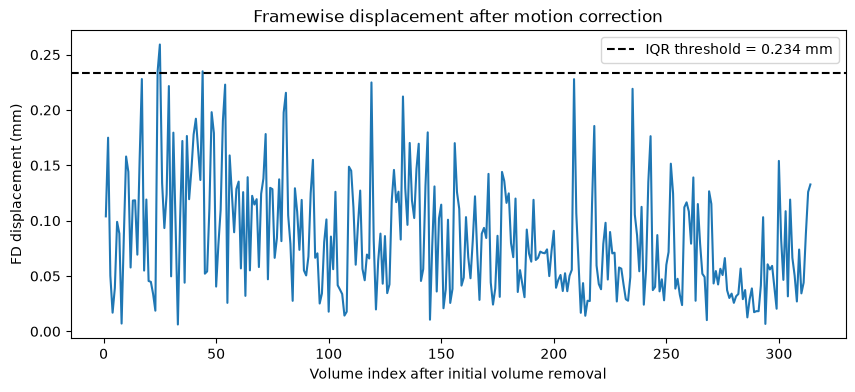

Mean FD: 0.0848 mm
Median FD: 0.0710 mm
Maximum FD: 0.2592 mm
IQR threshold: 0.2335 mm
Outlier volume indices: [24, 25, 44]
Outliers: 3 / 314 FD values


In [ ]:
# Compute Power framewise displacement (FD).
# FD measures frame-to-frame head movement using all six motion parameters estimated by MCFLIRT.
# Rotations are converted from radians to millimetres assuming a spherical head radius of 50 mm.

# difference between consecutive volumes
framewise_diff = mot_params.diff().iloc[1:]

# rotational displacement (radiants)
rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]

# convert rotations to equivalent displacement (mm)
converted_rots = rot_params*50

# total displacement (mm)
trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]

# sum of absolute rotational and translational differences
fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    


# idnetify unusually high motion 
threshold = np.quantile(fd,0.75) + 1.5*(np.quantile(fd,0.75) - np.quantile(fd,0.25))


# Data-driven outlier threshold: Q3 + 1.5 * IQR
# Identify unusually high motion:
fd_threshold = np.quantile(fd, 0.75) + 1.5*(np.quantile(fd, 0.75) - np.quantile(fd, 0.25))
# np.where(fd > fd_threshold)[0] find the indices of FD values exceeding the threshold
# FD[0] corresponds to the movement between volumes 0 and 1 of the trimmed fMRI series.
# Therefore, +1 gives the index of the later volume.
outliers  = np.where(fd > fd_threshold)[0] + 1

#%matplotlib inline
# Plot FD across the scan
plt.figure(figsize=(10, 4))
plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume index after initial volume removal')
plt.ylabel('FD displacement (mm)')
plt.title("Framewise displacement after motion correction")
plt.axhline(y=threshold,color="black",linestyle="--",label=f"IQR threshold = {threshold:.3f} mm")
plt.legend()
plt.show()

# Report summary statistics
print(f"Mean FD: {np.mean(fd):.4f} mm")
print(f"Median FD: {np.median(fd):.4f} mm")
print(f"Maximum FD: {np.max(fd):.4f} mm")
print(f"IQR threshold: {threshold:.4f} mm")

print("Outlier volume indices:", outliers.tolist())
print(f"Outliers: {len(outliers)} / {len(fd)} FD values")

### 2b Gaussian smoothing 

Gaussian spatial smoothing was applied to the motion-corrected fMRI data using FSL fslmaths, with a kernel of 6mm FWHM, corresponding to a standard deviation of approximately 2.55 mm.  

A 6 mm FWHM was selected as a compromise between improving the signal-to-noise ratio (SNR) and preserving spatial specificity; this follows the general rule that states that the FWHM should be either double or triple the voxel size of the fMRI image.   
Smoothing reduces high-frequency spatial noise by averaging neighbouring voxel intensities, but may also blur fine activation patterns.    

To assess its effect, the same functional volume (volume 100) was visualized before and after smoothing.


In [ ]:
# 6 mm FWHM (about 3x the 2 mm voxel); fslmaths takes sigma = FWHM / 2.3548
smoothed = moco + "_smoothed-6mm"
fwhm = 6.0
sigma = fwhm/2.3548

if not already_done("Smoothing", smoothed + '.nii.gz'):
    subprocess.run(['fslmaths', moco, '-s', str(sigma), smoothed], check=True)
    print("Smoothing completed")

print("Smoothing completed")
print("FWHM:", fwhm, "mm")
print("Sigma:", round(sigma, 3), "mm")

Functional voxel size (mm): (np.float32(2.0), np.float32(2.0), np.float32(2.0))


In [ ]:
# select one fMRI volume
vol = 100

if not already_done("Volume 100 snapshots", moco + "_vol100.nii.gz", smoothed + "_vol100.nii.gz"):
    fslroi(moco, moco + "_vol100", str(vol), str(1))
    fslroi(smoothed, smoothed + "_vol100", str(vol), str(1))

# visualize before and after smoothing
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(moco + "_vol100")
fsleyesDisplay.load(smoothed + "_vol100")

### 2c Validate the alignment between anatomical and functional data

The alignment between functional and anatomical images was visually assessed by overlaying a representative motion-corrected EPI volume onto the T1-weighted image previously normalized to MNI space using FLIRT and FNIRT.

In [ ]:
# Input: motion-corrected functional data
epi_source = moco

# whole and skull-stripped structural images 
whole_t1 = t1_path
skull_stripped_t1 = op.join(output_dir, "T1w_brain.nii.gz")

# output for EPI-to-T1 registration 
output_path = op.join(func_dir, "tfMRI_LANGUAGE_LR_moco_bbr")

# extract a representative functional volume 
ref_vol_name =  op.join(func_dir, "tfMRI_LANGUAGE_LR_moco_vol_middle")

use_single_vol = True

if use_single_vol:
    # Extract the middle volume with fslroi 
    n_volumes = nib.load(epi_source + ".nii.gz").shape[-1]
    middle_vol = n_volumes // 2
    fslroi(epi_source, ref_vol_name, str(middle_vol), str(1))
    print("Selected EPI volume:", middle_vol)

Selected EPI volume: 157


In [ ]:
# Inspect EPI and MNI image geometry

epi_img = nib.load(ref_vol_name + ".nii.gz")
mni_img = nib.load(t1_mni_nonlin)

print("EPI shape:", epi_img.shape)
print("EPI voxel size:", epi_img.header.get_zooms()[:3])
print("EPI affine:")
print(epi_img.affine)

print("\nRegistered T1 shape:", mni_img.shape)
print("Registered T1 voxel size:", mni_img.header.get_zooms()[:3])
print("Registered T1 affine:")
print(mni_img.affine)

# inspect native EPI against the T1 normalized to MNI 
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_mni_nonlin)
fsleyesDisplay.load(ref_vol_name)

EPI shape: (91, 109, 91)
EPI voxel size: (np.float32(2.0), np.float32(2.0), np.float32(2.0))
EPI affine:
[[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]

Registered T1 shape: (91, 109, 91)
Registered T1 voxel size: (np.float32(2.0), np.float32(2.0), np.float32(2.0))
Registered T1 affine:
[[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]


From the output above, the EPI volume and the T1 image normalized to MNI space have the same image dimensions, voxel size, and affine matrix.  

The initial overlay showed satisfactory spatial correspondence between the functional and anatomical images,
with no major misalignment of the brain boundaries or internal anatomical structures.   
This suggested that the functional data were already represented in the same standard MNI space as the anatomical image.

To further verify this observation, the same representative EPI volume was also registered to the subject’s native T1-weighted anatomical image. The resulting EPI-to-T1 affine transformation was then combined with the previously estimated nonlinear T1-to-MNI transformation from FNIRT, allowing the functional image to be transformed into MNI space.

In [47]:
# if the initial alignment is not good we register the functional EPI to the subject's anatomical T1 
# White matter partial-volume map from FAST (Part 1b)
wm_pve_path = op.join(output_dir, "T1w_fast_pve_2.nii.gz")
white_matter_segmentation = op.join(output_dir, "T1w_wm_mask.nii.gz") #saves it in a different file

subprocess.run([
    "fslmaths", wm_pve_path,
    "-thr", "0.5", "-bin", white_matter_segmentation
])
# register EPI to anatomical T1
subprocess.run(['epi_reg',"--epi=" + ref_vol_name, "--t1=" + whole_t1, "--t1brain=" + skull_stripped_t1, "--out=" + output_path, "--wmseg=" + white_matter_segmentation])

# EPI-to-T1 transformation matrix
epi_to_t1_mat = output_path + ".mat"

print("EPI-to-T1 matrix exists:", op.isfile(epi_to_t1_mat))

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(skull_stripped_t1)
fsleyesDisplay.load(output_path)

[Errno 1] Operation not permitted: '/home/jovyan/data/tsclient/NSSP/progetto/outputs/functional/tfMRI_LANGUAGE_LR_moco_bbr_fast_wmseg.nii.gz'
FLIRT pre-alignment
Running BBR
0.936580 0.999404 -0.033124 0.009704 0.000000 0.033670 0.997449 -0.062948 0.000000 -0.007594 0.063238 0.997970 0.000000 -6.041789 -3.269485 7.579045 1.000000 
EPI-to-T1 matrix exists: True



(ipykernel_launcher.py:1047): Gtk-WARNING **: 08:16:55.781: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)


In [ ]:
# now we combine:
# EPI --> T1 (the affine matrix)
# T1 --> MNI ( the non linear transformation obtained with FNIRT)

epi_mni_path = op.join(func_dir,"tfMRI_LANGUAGE_LR_vol_MNI.nii.gz")

# MNI reference used in Part 1c with FNIRT
mni_reference = mni_2mm

# Verify the required transformations
assert op.isfile(epi_to_t1_mat), "EPI-to-T1 matrix missing"
assert op.isfile(t1_mni_warp), "FNIRT warp missing"

# Apply combined transformation
subprocess.run(["applywarp", "--in=" + ref_vol_name,"--ref=" + mni_reference,"--warp=" + t1_mni_warp, "--premat=" + epi_to_t1_mat, "--out=" + epi_mni_path])

print("EPI successfully transformed to MNI space.")
print("Output exists:", op.isfile(epi_mni_path))

EPI successfully transformed to MNI space.
Output exists: True


In [ ]:
# quality control: anatomical-functional alignment in MNI
fsleyesDisplay.resetOverlays()

# Structural T1 after FLIRT + FNIRT
fsleyesDisplay.load(t1_mni_nonlin)

# Functional EPI transformed to MNI
fsleyesDisplay.load(epi_mni_path)

Comparison of the overlay before and after this additional registration showed no substantial improvement in anatomical correspondence. The functional and structural images were already well aligned prior to the extra EPI-to-T1 and T1-to-MNI transformation.  

Therefore, the additional functional-to-anatomical registration and subsequent transformation to MNI space can be omitted in this case. Avoiding this redundant step also prevents unnecessary interpolation and resampling of the functional data.


## 3) GLM

The goal of the GLM is to investigate the activation of the brain in the math and story tasks.

a) Build an appropriate experimental design matrix that you will use in the following GLM analysis.

b) Compute and plot the correlation matrix between the regressors of the design matrix and comment on the results.

c) Run the GLM at the level you deem reasonable and report the statistical maps of each of the task-related regressors. Briefly comment on the statistical maps.

d) Using the results of the GLM analysis and a contrast vector of your choice, create the activation maps corresponding to the story vs math
contrast. Please include in the report the contrast vector used and the contrast map you obtained.

e) Discuss which brain regions and networks are more activated during numerical than semantic processing, and which are more activated in the opposite contrast. As brain activity at rest can be separated into known functional networks [2], comment the results in terms of functional networks. Report known functional networks found within the statistical results and brain activation maps. You can either observe their overlaps or use brain atlas to inform your answer.

f) [Hard] Based on the literature, some regions should stand out as particularly relevant to semantic language processing. Are these regions present in your contrast maps? If not, discuss at least two possible reasons that could explain their absence.

## Loading data
The GLM needs one time series per voxel, since the preprocessed data is already 4D:

In [ ]:
from nilearn.glm.first_level import FirstLevelModel, make_first_level_design_matrix
from nilearn.glm.first_level.design_matrix import _make_drift
from nilearn.glm import threshold_stats_img
from nilearn.plotting import plot_design_matrix, plot_contrast_matrix, plot_stat_map
from nilearn.image import mean_img

# Preprocessed 4D data: volume removed, motion-corrected, smoothed
fmri_img = nib.load(smoothed + ".nii.gz")

# Number of volumes after the preprocessing:
n_scans = fmri_img.shape[-1]

# Acquisition time of each volume of the trimmed series: 0, TR, 2TR, ...
frame_times = np.arange(n_scans) * tr

Regarding the events, Nilearn needs a DataFrame with exactly three columns: onset (s), duration (s) and trial_type. Each unique trial_type becomes one regressor. 

In [ ]:
# Defining the path of the events
events_path = os.path.join(data_dir, 'fMRI', 'tfMRI_LANGUAGE_LR', 'tfMRI_LANGUAGE_LR_task_onsets.csv')

# Reading and printing the events
events = pd.read_csv(events_path)

# Since we removed "start_vol" volumes, the "t = 0" shifted, therefore 
# we need to shift all the onsets: 
events['onset'] = events['onset'] - start_vol * tr

# Keep only the task blocks: sub-events (present/question/response) are
# contained in the blocks and would create near-identical regressors
events_sm = events[events['trial_type'].isin(['story', 'math'])].copy()
print(events_sm)
events_pqr = events[events['trial_type'].isin(['present_story', 'question_story', 'response_story', 'present_math', 'question_math', 'response_math'])].copy()
print(events_pqr)

      onset  duration trial_type
0    -0.479    28.270      story
6    29.375    12.241       math
10   41.850    12.312       math
15   55.804    27.147      story
19   84.486    12.667       math
24   97.400    12.542       math
29  111.554    26.070      story
33  139.210    11.844       math
38  151.325    12.528       math
42  164.133     9.838       math
45  174.208    12.176       math
51  188.016    29.301      story
55  218.883    12.574       math
      onset  duration      trial_type
1    -0.479    20.445   present_story
2    20.472     1.161  question_story
3    24.830     2.961  response_story
5    29.375     5.667    present_math
7    35.226     3.391   question_math
8    38.651     2.965   response_math
9    41.850     5.453    present_math
11   47.461     3.702   question_math
12   51.206     2.956   response_math
14   55.804    19.821   present_story
16   76.129     1.162  question_story
17   79.994     2.957  response_story
20   84.486     6.224    present_math
21   9

## 3a. Building the design matrix
In order to build the GLM, first of all we need to specify EXPLAIN

We decided to add the following regressors: 
- Signal drift (slow scanner or physiological trends, modelled as low-order polynomials or cosines)
- Censoring (explain what it is)
- Motion parameters

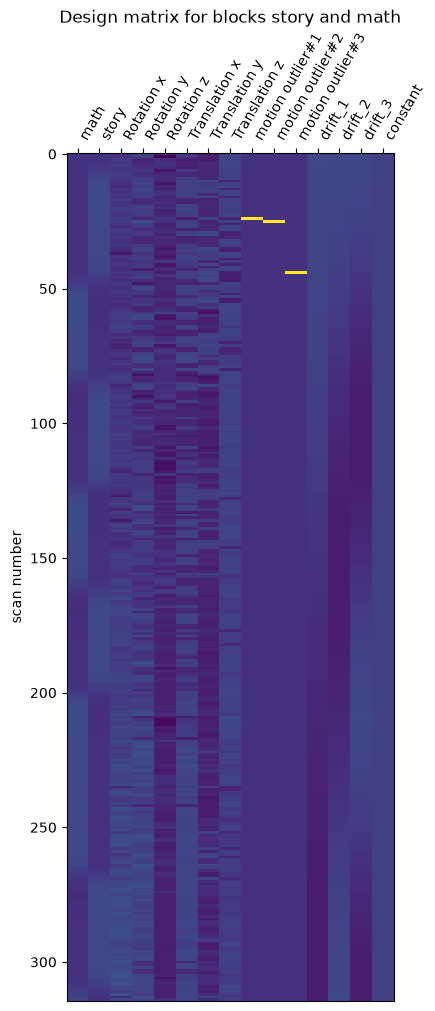

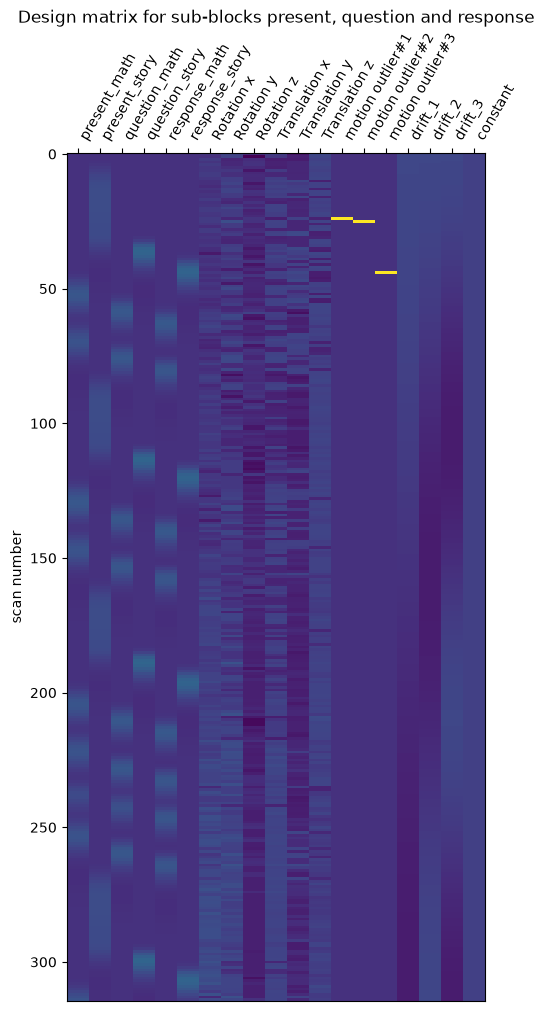

In [ ]:
# Defining the regressors: 6 motion parameters from MCFLIRT
# Chek there is exacly one line per volume
assert len(mot_params) == n_scans   
# Define the confounds as the motion paramters, in order to add other regressors later on
confounds = mot_params.copy()


# Defining the regressors: censoring
# One "spike" regressor per FD outlier (1 on that volume, 0 elsewhere) is added
for i, v in enumerate(outliers):
    reg = np.zeros((n_scans,))
    reg[v] = 1.0
    confounds['motion outlier#' + str(i+1)] = reg


# Defining the design matrix keeping only the math and story block, dropping all the sub-blocks
design_mat_sm = make_first_level_design_matrix(frame_times,
                                            events_sm,
                                            hrf_model='spm',
                                            drift_model='polynomial',
                                            drift_order=3,
                                            add_regs=confounds.values,
                                            add_reg_names=list(confounds.columns))

# Defining the design matrix keeping all the sub-blocks, dropping the two math and story blocks
design_mat_pqr = make_first_level_design_matrix(frame_times,
                                            events_pqr,
                                            hrf_model='spm',
                                            drift_model='polynomial',
                                            drift_order=3,
                                            add_regs=confounds.values,
                                            add_reg_names=list(confounds.columns))

plot_design_matrix(design_mat_sm)
plt.title('Design matrix for blocks story and math')
plt.show()

plot_design_matrix(design_mat_pqr)
plt.title('Design matrix for sub-blocks present, question and response')
plt.show()

## 3b. Correlation between regressors

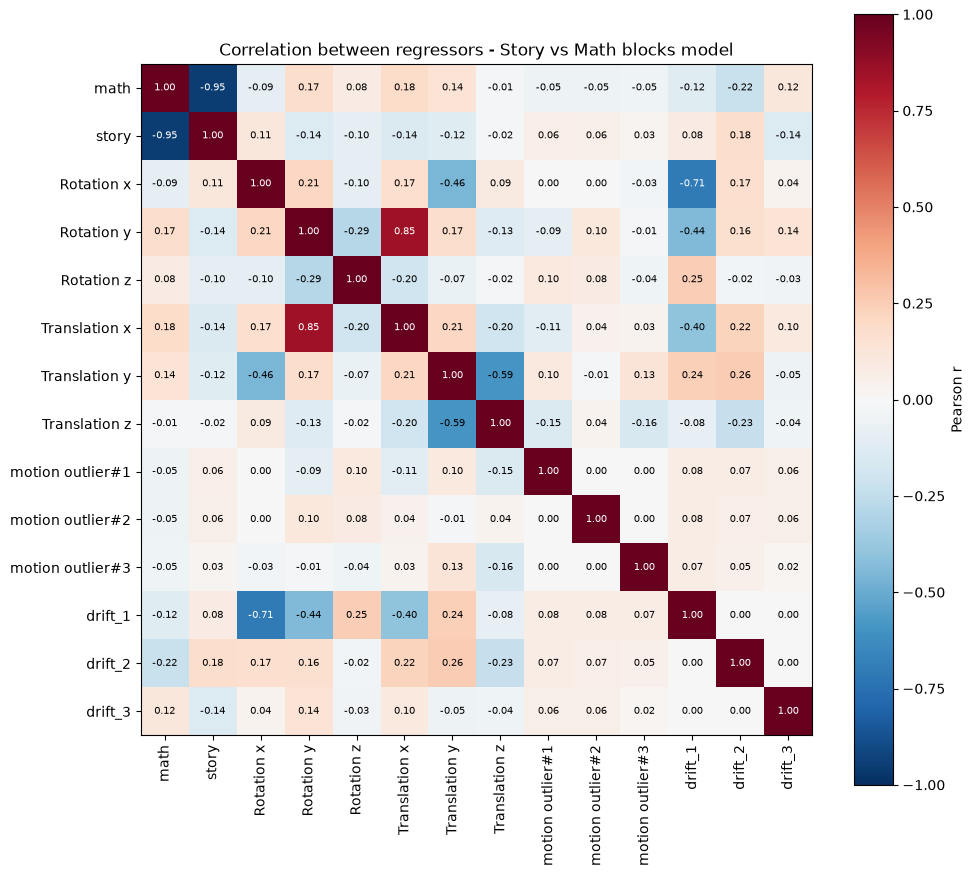

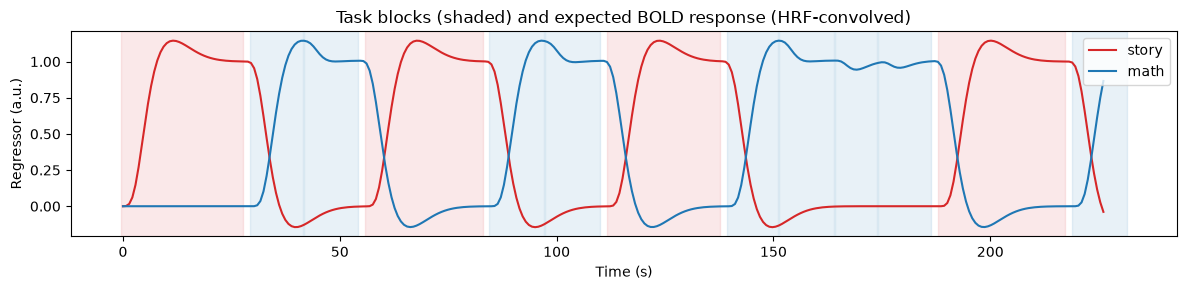

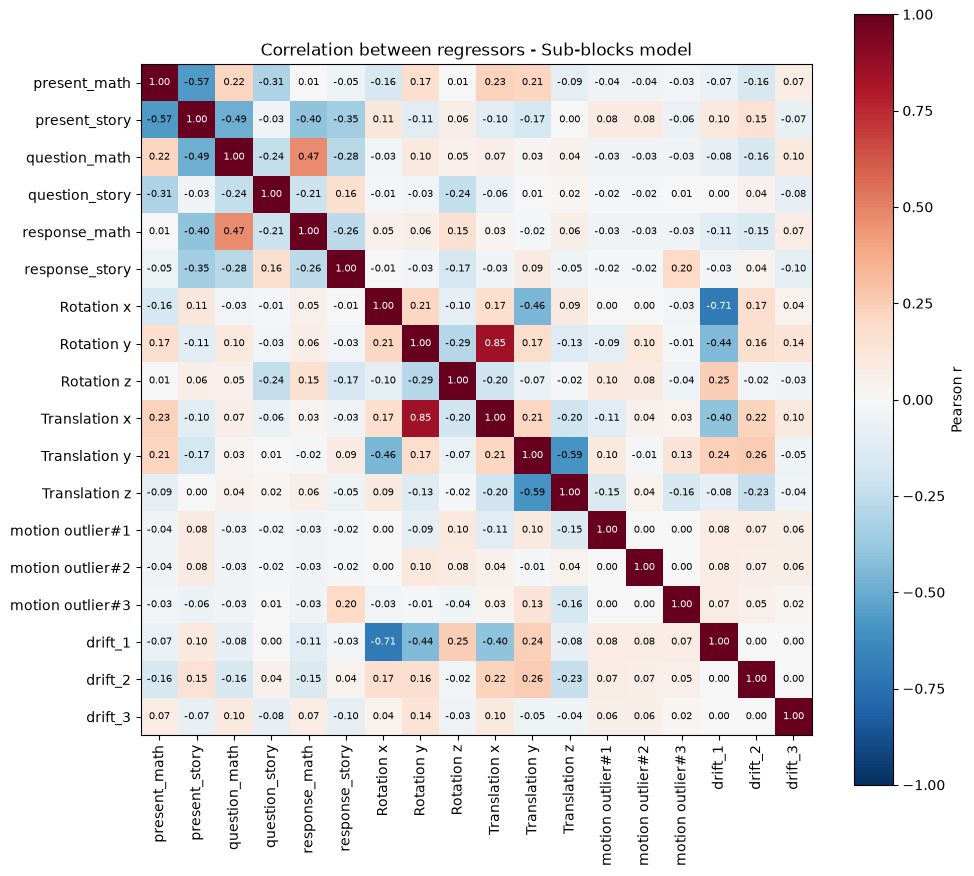

In [ ]:
# Since the constant regressor has zero variance, the correlation would be NaN, therefore we do not consider it:
cols = [c for c in design_mat_sm.columns if c != 'constant'] # the two blocks model
corr = design_mat_sm[cols].corr()

# Plotting the correlation matrix for the two blocks model
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='Pearson r')
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)

# Write r in every cell
for i in range(len(corr)):
    for j in range(len(corr)):
        r = round(corr.iloc[i, j], 2) + 0.0       # + 0.0 turns -0.0 into 0.0
        ax.text(j, i, '{:.2f}'.format(r), ha='center', va='center', fontsize=7,
                color='white' if abs(r) > 0.6 else 'black')

ax.set_title('Correlation between regressors - Story vs Math blocks model')
plt.tight_layout()
plt.show()

# Plotting the BOLD response for the two-blocks model
fig, ax = plt.subplots(figsize=(12, 3))
for cond, color in [('story', 'tab:red'), ('math', 'tab:blue')]:
    # Shaded area = when the condition is on (the boxcar before convolution)
    for _, block in events_sm[events_sm['trial_type'] == cond].iterrows():
        ax.axvspan(block['onset'], block['onset'] + block['duration'], color=color, alpha=0.1)
    # Line = expected BOLD response (boxcar convolved with the HRF)
    ax.plot(frame_times, design_mat_sm[cond], color=color, label=cond)

ax.set(xlabel='Time (s)', ylabel='Regressor',
       title='Task blocks (shaded) and expected BOLD response (HRF-convolved)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()



cols = [c for c in design_mat_pqr.columns if c != 'constant'] # the sub-blocks model
corr = design_mat_pqr[cols].corr()

# Plotting the correlation matrix
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='Pearson r')
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)

# Write r in every cell
for i in range(len(corr)):
    for j in range(len(corr)):
        r = round(corr.iloc[i, j], 2) + 0.0       # + 0.0 turns -0.0 into 0.0
        ax.text(j, i, '{:.2f}'.format(r), ha='center', va='center', fontsize=7,
                color='white' if abs(r) > 0.6 else 'black')

ax.set_title('Correlation between regressors - Sub-blocks model')
plt.tight_layout()
plt.show()

## 3c. Fitting the model
Since there is only one subject, we need to condutc a first level analysis. 

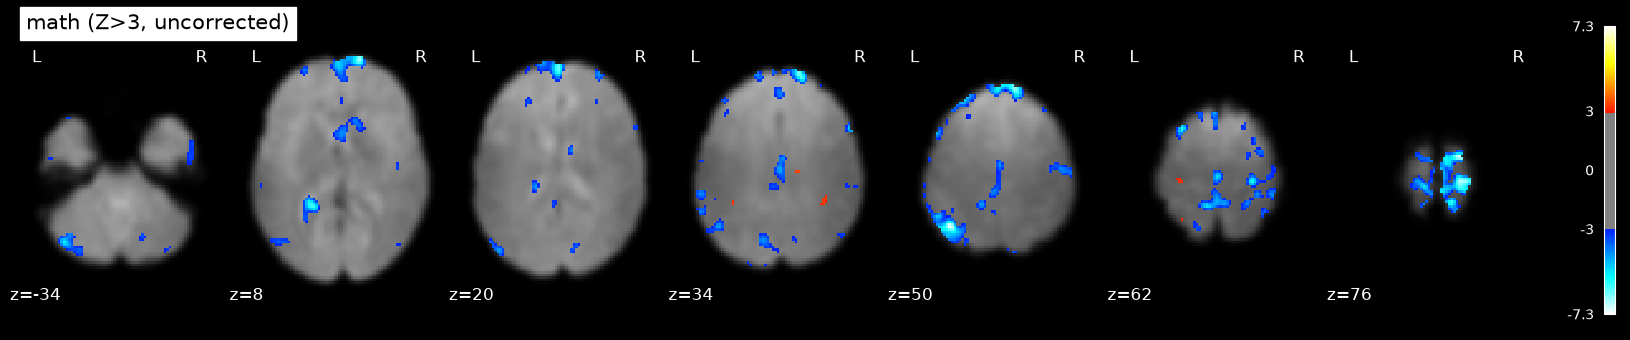

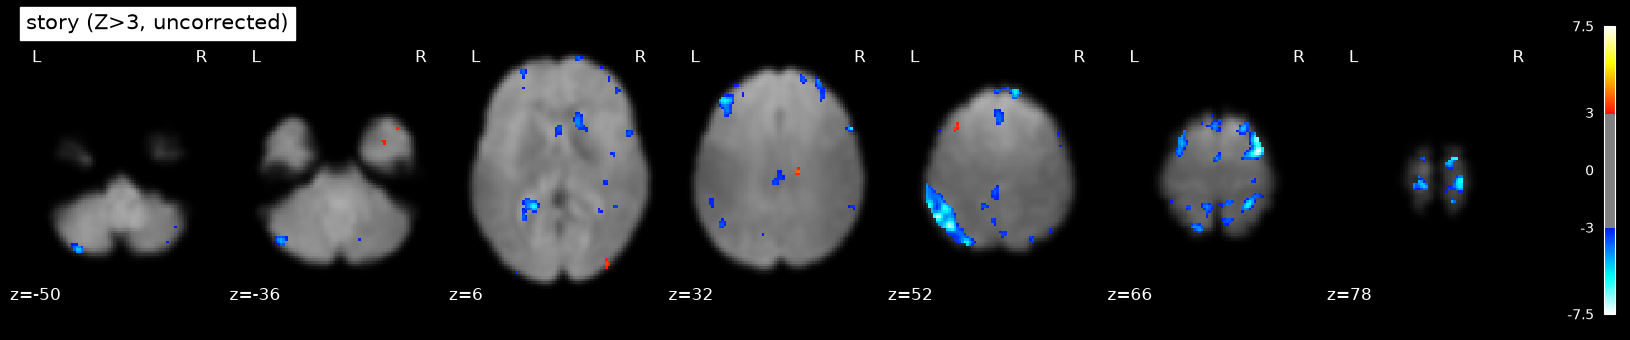

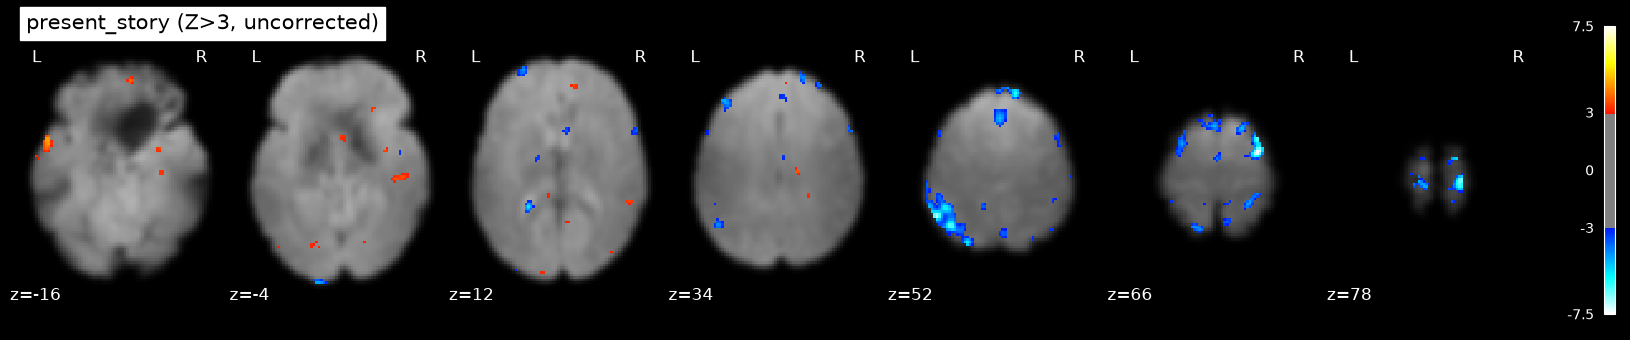

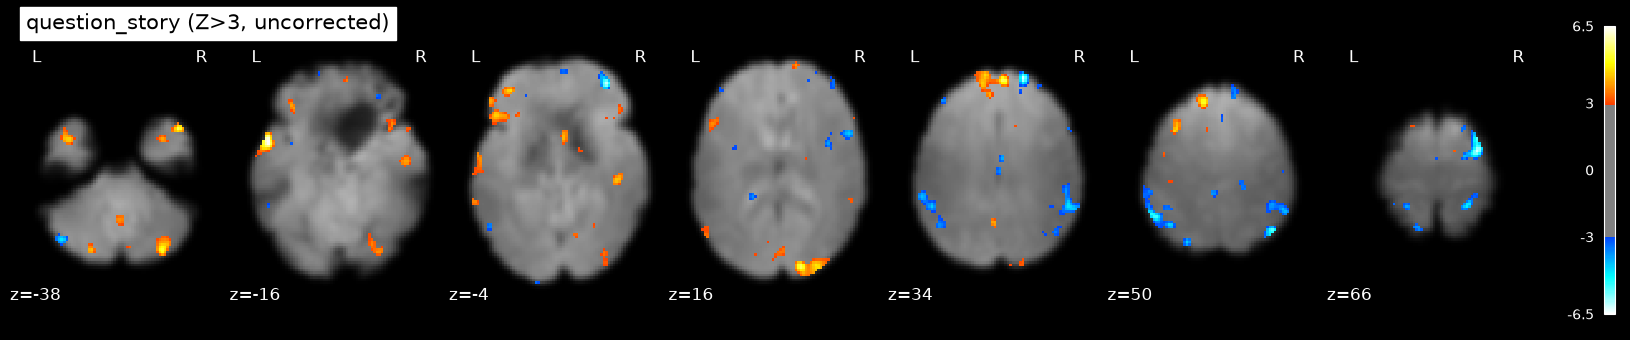

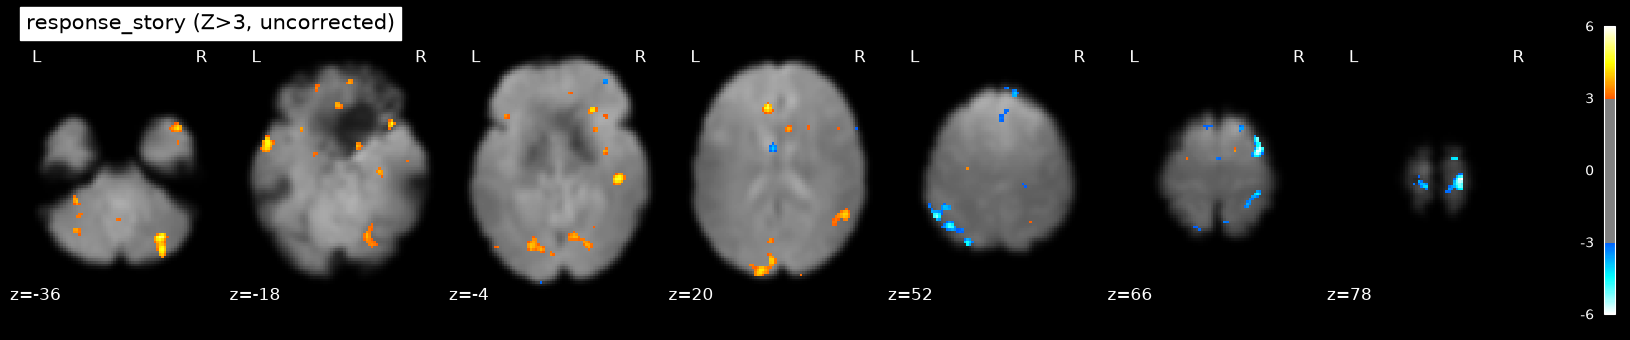

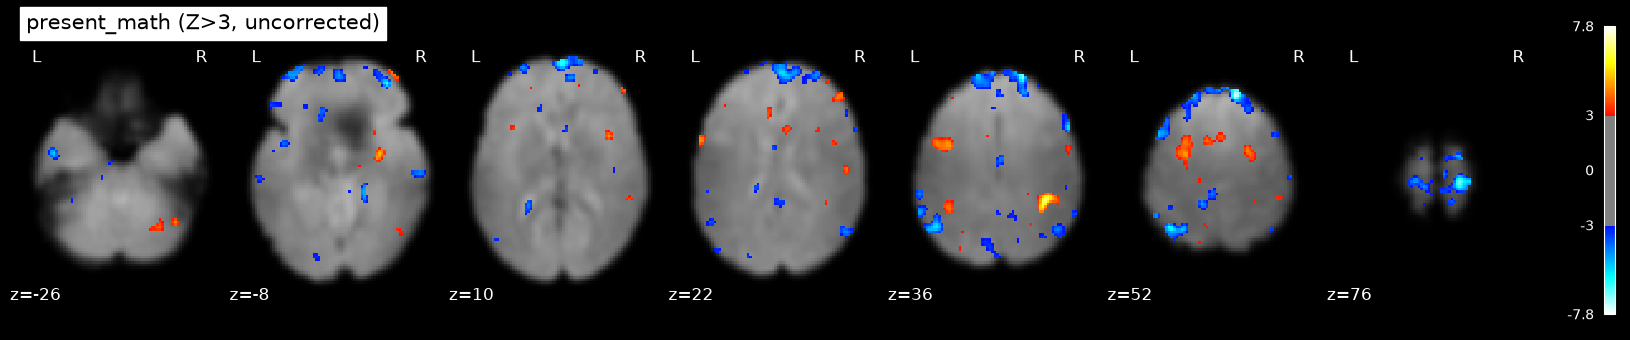

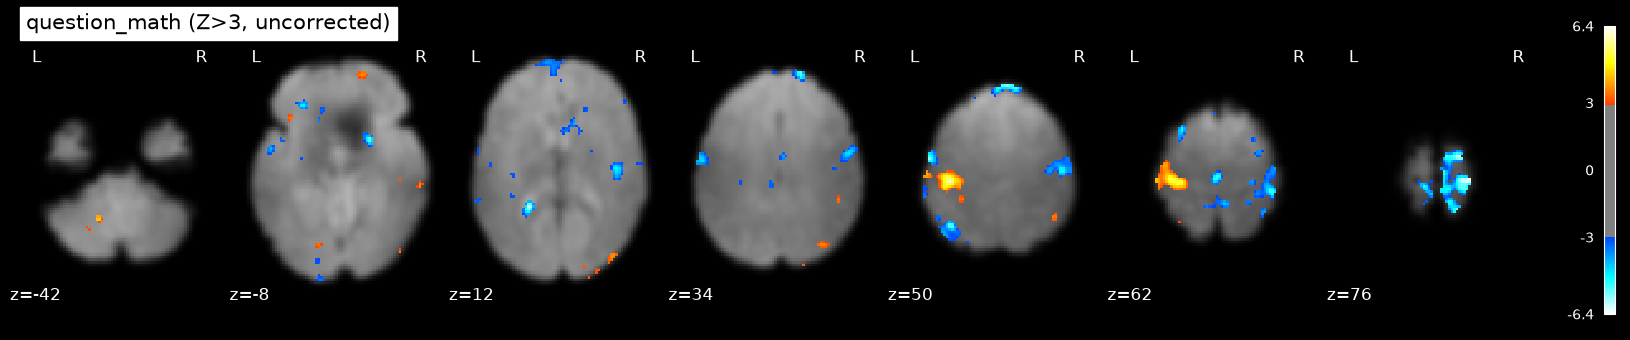

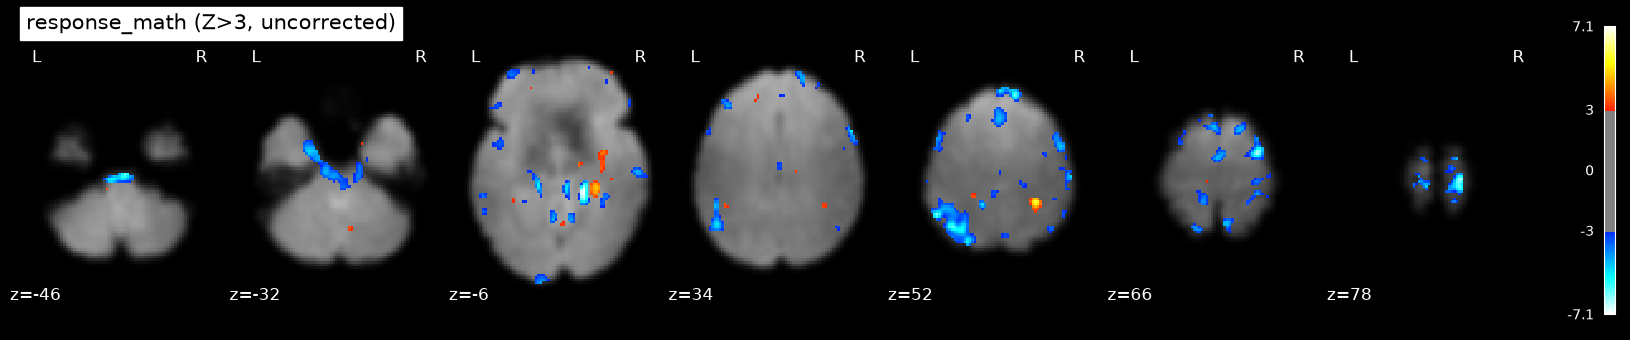

In [ ]:
# First fitting for the story vs math blocks:
fit_glm_sm = FirstLevelModel(t_r=tr,
                          noise_model='ar1',
                          standardize=False)
fit_glm_sm = fit_glm_sm.fit(fmri_img, design_matrices=[design_mat_sm])

# Defining one contrast vector per condition: 1 on its column, 0 elsewhere.
# It is built from the column names so it doesn't depend on column order.
conditions_sm = {}
for cond in ['math', 'story']:
    conditions_sm[cond] = np.zeros(design_mat_sm.shape[1])
    conditions_sm[cond][design_mat_sm.columns.get_loc(cond)] = 1

# Mean functional image, used as background
mean_fmri = mean_img(fmri_img)

for cond in ['math', 'story']:
    z_map_cond = fit_glm_sm.compute_contrast(conditions_sm[cond], output_type='z_score')
    nib.save(z_map_cond, op.join(func_dir, 'z_map_{}.nii.gz'.format(cond)))
    plot_stat_map(z_map_cond, bg_img=mean_fmri, threshold=3.0,
                  display_mode='z', cut_coords=7, black_bg=True,
                  title='{} (Z>3, uncorrected)'.format(cond))
    plt.show()


# Second fitting for the sub-blocks model: 
fit_glm_pqr = FirstLevelModel(t_r=tr,
                          noise_model='ar1',
                          standardize=False)
fit_glm_pqr = fit_glm_pqr.fit(fmri_img, design_matrices=[design_mat_pqr])

# Defining one contrast vector per condition: 1 on its column, 0 elsewhere.
# It is built from the column names so it doesn't depend on column order.
conditions_pqr = {}
for cond in ['present_story', 'question_story', 'response_story', 'present_math', 'question_math', 'response_math']:
    conditions_pqr[cond] = np.zeros(design_mat_pqr.shape[1])
    conditions_pqr[cond][design_mat_pqr.columns.get_loc(cond)] = 1


for cond in ['present_story', 'question_story', 'response_story', 'present_math', 'question_math', 'response_math']:
    z_map_cond = fit_glm_pqr.compute_contrast(conditions_pqr[cond], output_type='z_score')
    nib.save(z_map_cond, op.join(func_dir, 'z_map_{}.nii.gz'.format(cond)))
    plot_stat_map(z_map_cond, bg_img=mean_fmri, threshold=3.0,
                  display_mode='z', cut_coords=7, black_bg=True,
                  title='{} (Z>3, uncorrected)'.format(cond))
    plt.show()

## 3d. Contrast and activation maps "story vs math"

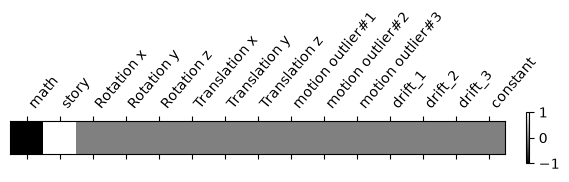

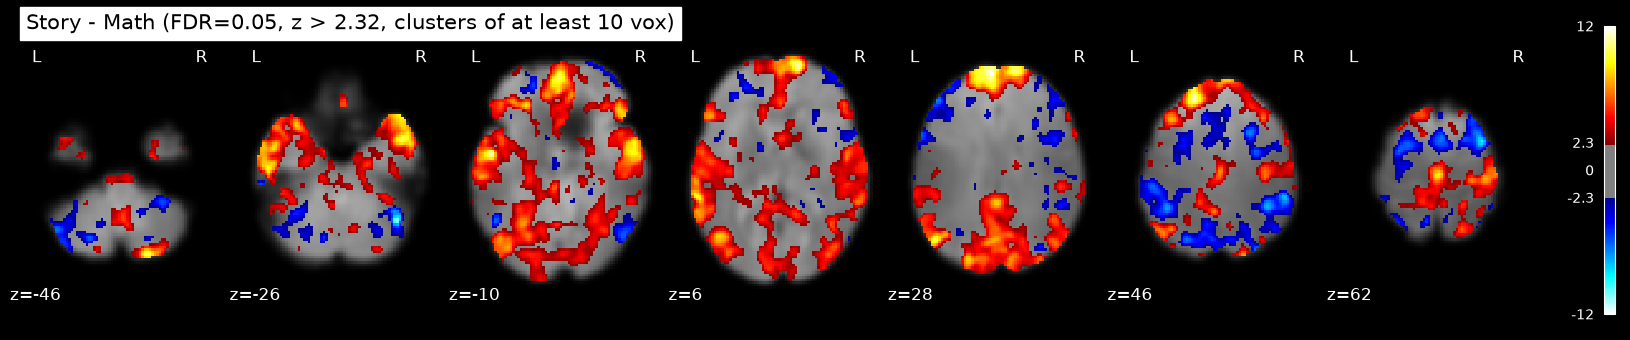

In [ ]:
# For the two blocks model, the constrast is simply c = +1 on story, -1 on math, 0 elsewhere 
# This corresponds to tests beta_story - beta_math, therefore, a positive z means story > math; while 
# a negative z means math > story
story_minus_math = conditions_sm['story'] - conditions_sm['math']

plot_contrast_matrix(story_minus_math, design_matrix=design_mat_sm, colorbar=True)
plt.show()

z_map = fit_glm_sm.compute_contrast(story_minus_math, output_type='z_score')
nib.save(z_map, op.join(func_dir, 'z_map_story_minus_math.nii.gz'))

# Multiple-comparison correction: FDR 5% + clusters of at least 10 voxels
cluster_size = 10
fdr_rate = 0.05
clean_map, threshold = threshold_stats_img(z_map, alpha=fdr_rate, height_control='fdr', cluster_threshold=cluster_size)
nib.save(clean_map, op.join(func_dir, 'story_minus_math_fdr.nii.gz'))

# Plotting the activation map for "story - math"
plot_stat_map(clean_map, bg_img=mean_fmri, threshold=threshold,
              display_mode='z', cut_coords=7, black_bg=True,
              title='Story - Math (FDR={}, Threshold: z > {:.2f}, clusters of at least {} vox)'.format(fdr_rate, threshold, cluster_size))
plt.show()

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(func_dir, 'story_minus_math_fdr.nii.gz'))

For the sub-events model we can implement different contrasts: 
1. Story - math where every sub-block is weighted by their duration
2. Story presentation - math presentation
3. Story question - math question
4. Story response - math response

story_minus_math_pqr  (sum of weights = 0.00)


Regressor,Weight
present_math,-0.46
present_story,+0.83
question_math,-0.29
question_story,+0.05
response_math,-0.25
response_story,+0.12
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


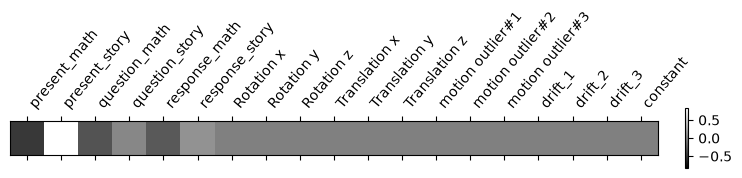

story_minus_math_pqr | z threshold: 2.33 | story>math voxels: 66081 | math>story voxels: 20233


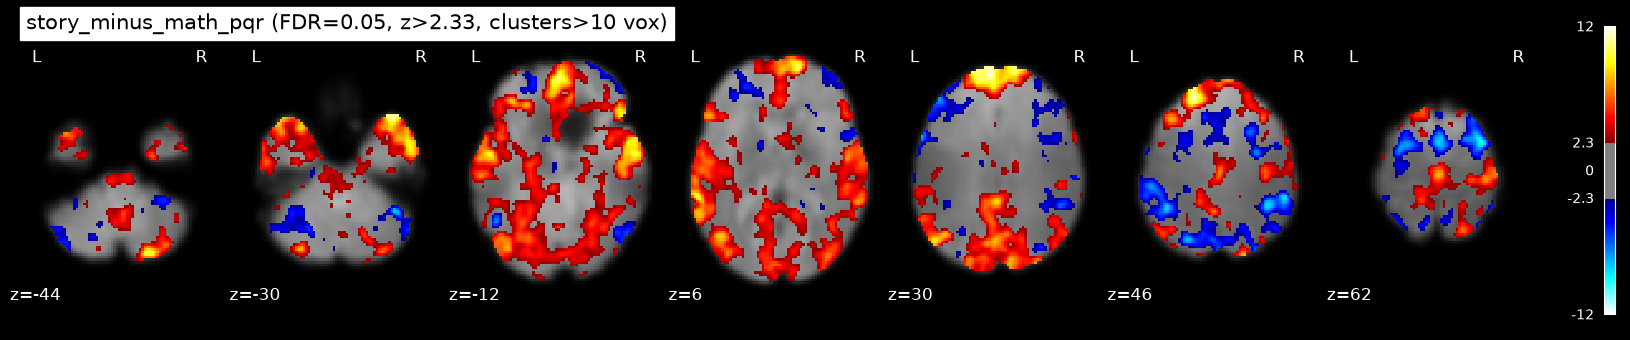

present_story_minus_present_math  (sum of weights = 0.00)


Regressor,Weight
present_math,-1.00
present_story,+1.00
question_math,+0.00
question_story,+0.00
response_math,+0.00
response_story,+0.00
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


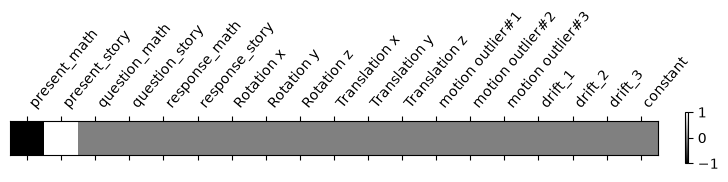

present_story_minus_present_math | z threshold: 2.43 | story>math voxels: 36782 | math>story voxels: 28832


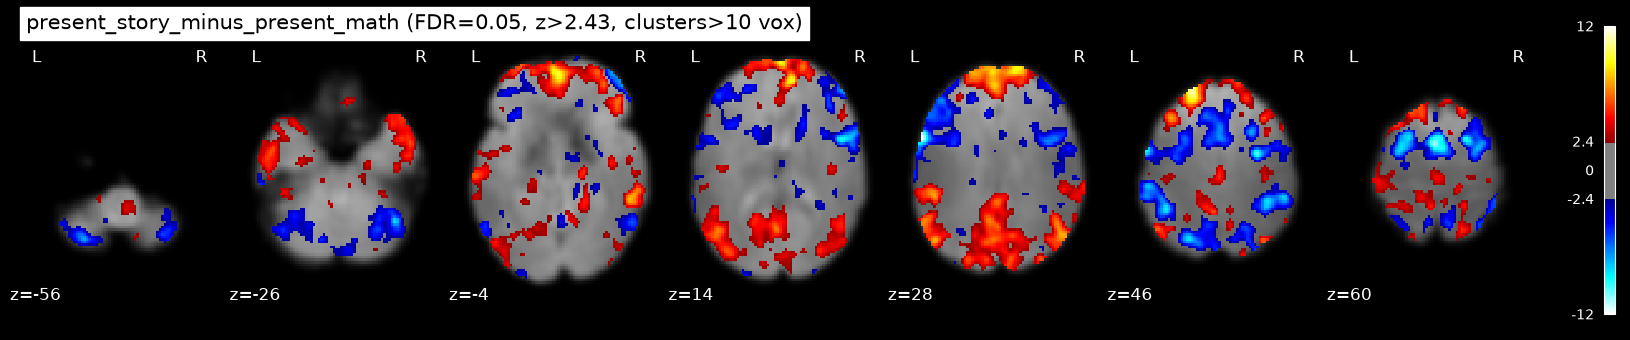

question_story_minus_question_math  (sum of weights = 0.00)


Regressor,Weight
present_math,+0.00
present_story,+0.00
question_math,-1.00
question_story,+1.00
response_math,+0.00
response_story,+0.00
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


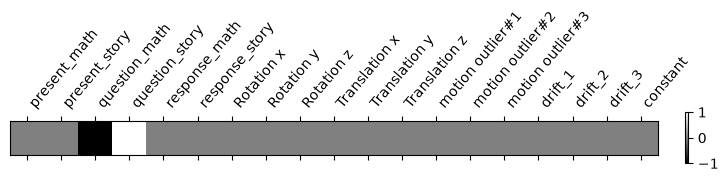

question_story_minus_question_math | z threshold: 2.96 | story>math voxels: 8546 | math>story voxels: 4340


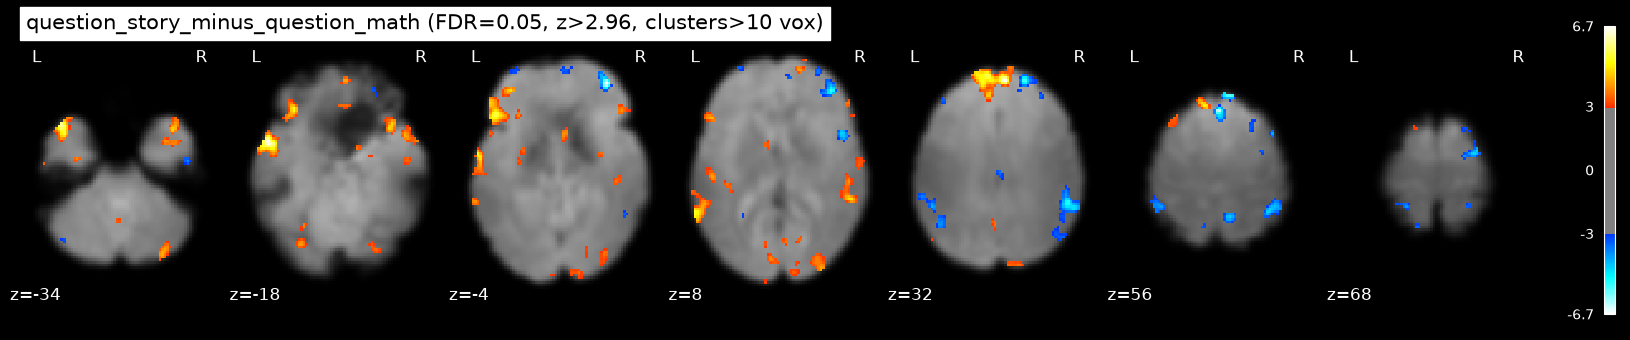

response_story_minus_response_math  (sum of weights = 0.00)


Regressor,Weight
present_math,+0.00
present_story,+0.00
question_math,+0.00
question_story,+0.00
response_math,-1.00
response_story,+1.00
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


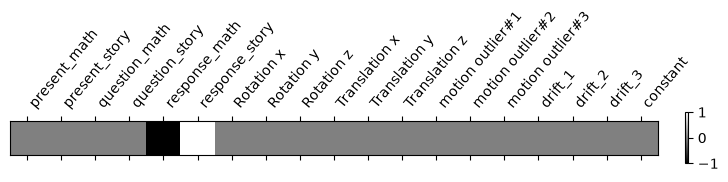

response_story_minus_response_math | z threshold: 2.72 | story>math voxels: 27647 | math>story voxels: 236


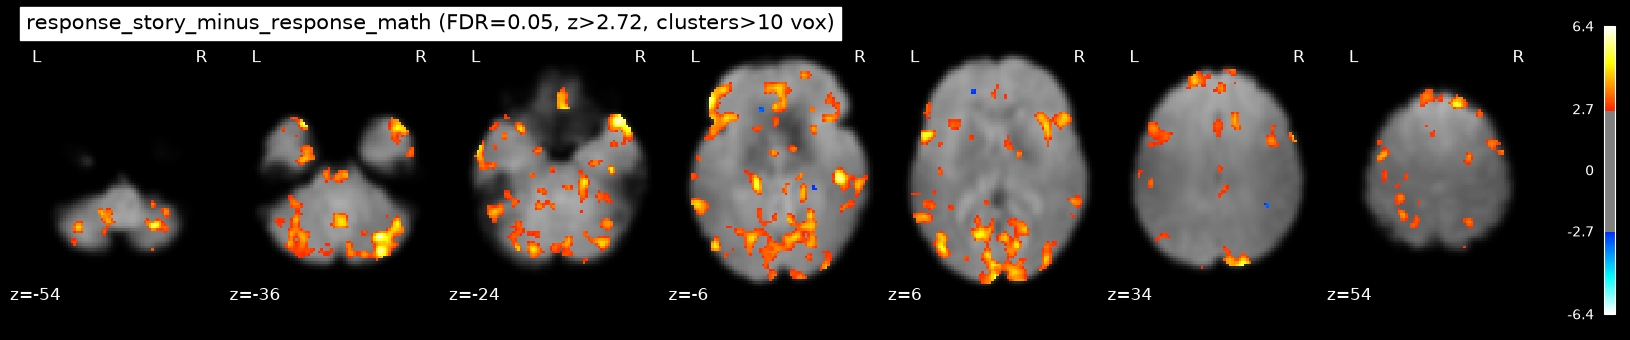

In [ ]:
# Sub-event model: story - math (duration-weighted) + the three phase-by-phase differences

# Duration-weighted story - math: each phase weighted by its share of the condition's
# total time, so it asks the same question as the block model (story sums to +1, math to -1)
dur = events_pqr.groupby('trial_type')['duration'].sum()
story_phases = ['present_story', 'question_story', 'response_story']
math_phases = ['present_math', 'question_math', 'response_math']

story_minus_math_pqr = np.zeros(design_mat_pqr.shape[1])
for t in story_phases:
    story_minus_math_pqr += conditions_pqr[t] * dur[t] / dur[story_phases].sum()
for t in math_phases:
    story_minus_math_pqr -= conditions_pqr[t] * dur[t] / dur[math_phases].sum()

contrasts_pqr = {
    'story_minus_math_pqr': story_minus_math_pqr,
    'present_story_minus_present_math': conditions_pqr['present_story'] - conditions_pqr['present_math'],
    'question_story_minus_question_math': conditions_pqr['question_story'] - conditions_pqr['question_math'],
    'response_story_minus_response_math': conditions_pqr['response_story'] - conditions_pqr['response_math'],
}

z_maps_pqr = {}
for name, contrast in contrasts_pqr.items():
    # One weight per column of the model actually used
    assert len(contrast) == fit_glm_pqr.design_matrices_[0].shape[1]
    df = pd.DataFrame(
        {"Regressor": design_mat_pqr.columns,
         "Weight": [float(v) for v in contrast]}
    )
    print(f"{name}  (sum of weights = {df['Weight'].sum():.2f})")
    display(df.style.hide(axis="index").format({"Weight": "{:+.2f}"}))

    plot_contrast_matrix(contrast, design_matrix=design_mat_pqr, colorbar=True)
    plt.show()

    z_maps_pqr[name] = fit_glm_pqr.compute_contrast(contrast, output_type='z_score')
    nib.save(z_maps_pqr[name], op.join(func_dir, 'z_map_{}.nii.gz'.format(name)))

    clean_map_pqr, z_threshold_pqr = threshold_stats_img(z_maps_pqr[name], alpha=fdr_rate,
                                                         height_control='fdr',
                                                         cluster_threshold=cluster_size)
    nib.save(clean_map_pqr, op.join(func_dir, '{}_fdr.nii.gz'.format(name)))

    c = clean_map_pqr.get_fdata()
    print(name, '| z threshold: {:.2f} | story>math voxels: {} | math>story voxels: {}'.format(
        z_threshold_pqr, (c > 0).sum(), (c < 0).sum()))

    if np.isfinite(z_threshold_pqr):
        plot_stat_map(clean_map_pqr, bg_img=mean_fmri, threshold=z_threshold_pqr,
                      display_mode='z', cut_coords=7, black_bg=True,
                      title='{} (FDR={}, Threshold: z > {:.2f}, clusters of at least {} vox)'.format(name, fdr_rate, z_threshold_pqr, cluster_size))
        plt.show()
    else:
        print(name, ': no voxel survives FDR')

In [ ]:
# In order to decide which regressors is better to keep, it is possible to compare the previous results
# using the block-model "story - math" as the reference:
z_ref = z_map.get_fdata()
c = clean_map.get_fdata()
print('{:36s} | story > math voxels: {} | math > story voxels: {} | peak |z|: {:.2f}'.format(
    'Block model "story - math"', (c > 0).sum(), (c < 0).sum(), np.abs(z_ref).max()))

# Spatial correlation of each sub-event map with the block map, inside the brain
for name, zm in z_maps_pqr.items():
    z = zm.get_fdata()
    inside = (z != 0) & (z_ref != 0)
    print('{:36s} | r with block story-math: {:.3f} | peak |z|: {:.2f}'.format(
        name, np.corrcoef(z[inside], z_ref[inside])[0, 1], np.abs(z).max()))

Block model "story - math"           | story > math voxels: 66160 | math > story voxels: 21369 | peak |z|: 12.17
story_minus_math_pqr                 | r with block story-math: 0.981 | peak |z|: 12.07
present_story_minus_present_math     | r with block story-math: 0.842 | peak |z|: 12.19
question_story_minus_question_math   | r with block story-math: 0.445 | peak |z|: 6.71
response_story_minus_response_math   | r with block story-math: 0.363 | peak |z|: 6.41


Since the correlation between the block-model "story - math" and the sub-block model weighted by the duration have a correlation of 0.981, they are very similar. This means we can use the simpler model without loosing too much information?????

## 3e. Brain regions and networks activated during numerical and semantic processing

In order to identify which brain regions and networks are more activated during numerical than semantic processing, and which are more activated in the opposite contrast, we need to use two atlases: 

- The Yeo atlas, that gives the network answer. Indeed, even when you lie in the scanner doing nothing, some brain areas rise and fall together. Yeo et all. (reference [2]) measured this in about 1000 people and found 7 networks:
    - Visual: seeing.
    - Somatomotor: moving and touch, and in this atlas also hearing.
    - Dorsal Attention: focusing on things outside you.
    - Ventral Attention: noticing what’s important.
    - Limbic: emotion and memory, at the bottom of the brain.
    - Frontoparietal: effortful thinking, the brain’s “control” system.
    - Default: thinking about meaning, stories, yourself, memories.
- The Harvard-Oxford atlas, that gives the anatomical answer.

An atlas is a brain image where every voxel carries a label instead of a measurement: “this voxel belongs to network 7” and so on. Our data is already in the same standard brain space (MNI) as the atlas, so we can just lay our activation map on top of the atlas and, for each network, count how many of our significant voxels fall inside it. More specifically, for each network we need to measure: 
1. What share of the story (or math) activation lands in this network, that tells where the activation lives.
2. What share of the network lights up, that tells how strongly the network is engaged. Otherwise, big networks would win just by being big.

In [ ]:
from nilearn.image import resample_to_img
import xml.etree.ElementTree as ET

# Loading the Yeo 2011, liberal cortical mask: a local file downloaded directly from the 
# paper resources
yeo_path = op.join(data_dir, 'atlas', 'Yeo2011_7Networks_MNI152_FreeSurferConformed1mm_LiberalMask.nii')
# Unfortunately, the atlas is on a 1mm template, and our image is on a 2mm. Therefore, we have to resample the atlas
# in the right grid (the one contained in clean_map). During the resampling, each new voxel copies the label of the closest 
# old voxel, so the labels stay whole numbers 0–7. We then remove the 4th dimension that the atlas file has (using squueze)
yeo_data = np.squeeze(resample_to_img(yeo_path, clean_map, interpolation='nearest').get_fdata())
yeo_names = ['Visual', 
             'Somatomotor', 
             'Dorsal Attention', 
             'Ventral Attention', 
             'Limbic', 
             'Frontoparietal', 
             'Default']

# Loading the Harvard-Oxford cortical atlas from FSL (already on the 2 mm grid)
ho_img = nib.load(op.expandvars('$FSLDIR/data/atlases/HarvardOxford/HarvardOxford-cort-maxprob-thr25-2mm.nii.gz'))
ho_data = ho_img.get_fdata()
ho_labels = {}
for type_tag in ET.parse(op.expandvars('$FSLDIR/data/atlases/HarvardOxford-Cortical.xml')).getroot().findall('data/label'):
    ho_labels[int(type_tag.get('index')) + 1] = type_tag.text


# In order to make the analysis we need to re-use the z-map with only the 
# significant voxels, so we can take the thresholded activation map and save it in an array. 
# At the same time, it is also useful to define two true or false arrays that are 
# true where story > math is significant or viceversa, in order to use them as masks to only use 
# the values of interest from the cleaned map. 
clean = clean_map.get_fdata()
story_gt_math = clean > 0 # true where story > math is significant
math_gt_story = clean < 0 # true where math > story is significant


print('Atlas grids match the z-map:', yeo_data.shape == clean.shape == ho_data.shape)
print('Story > math voxels: {} | math > story voxels: {}'.format(story_gt_math.sum(), math_gt_story.sum()))

Atlas grids match the z-map: True
Story > math voxels: 66160 | math > story voxels: 21369


,% of network where story > math,% of network where math > story,% of significant story > math voxels that land in this newtwork,% of significant math > story voxels that land in this newtork
Network,,,,
Visual,53.0,2.3,17.8,2.3
Somatomotor,49.2,2.0,14.5,1.9
Dorsal Attention,14.3,30.9,3.3,22.1
Ventral Attention,21.3,15.3,4.4,9.8
Limbic,33.1,1.2,5.8,0.7
Frontoparietal,10.4,30.9,3.1,28.2
Default,60.1,2.7,27.4,3.9


Significant voxels outside the Yeo cortex: 23.7 % (story>math), 31.1 % (math>story)


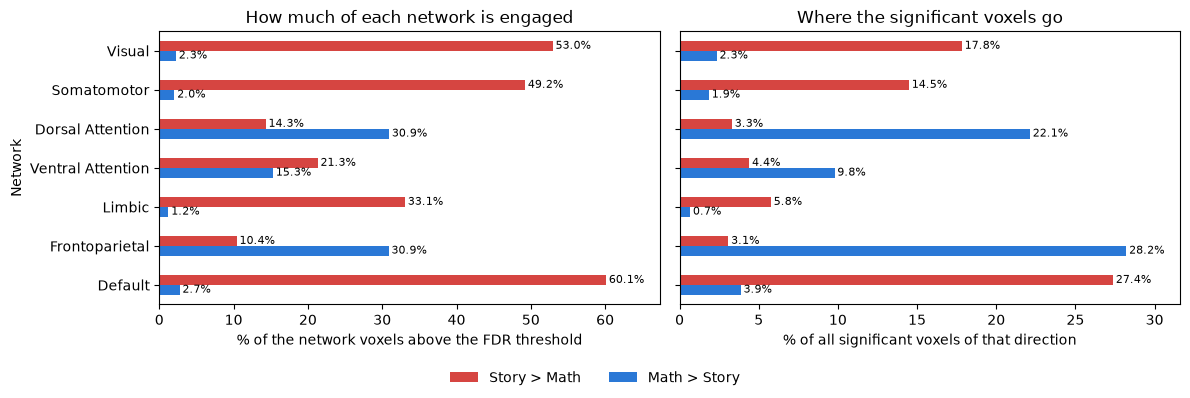

In [ ]:
# In order to know which networks are involved, it is possible to count the number of significant voxels 
# in both directions (math is more active, story is more active) that are present in that specific network.
# To avoid loops on every single voxel we can define a true/false mask for each network. In this way the 
# number of true elements in the mask is the number of voxels in the network; and by checking where both the 
# conditions are true (the voxel is in the network and is significant for story > math or viceversa) we can count
# the number of voxels that fall in the network.
rows = []
for k, name in enumerate(yeo_names, start=1):
    net = yeo_data == k   # mask of network k (as make_mask_from_atlas in lab 1)
    rows.append([name,
                 100 * (net & story_gt_math).sum() / net.sum(),
                 100 * (net & math_gt_story).sum() / net.sum(),
                 100 * (net & story_gt_math).sum() / story_gt_math.sum(),
                 100 * (net & math_gt_story).sum() / math_gt_story.sum()])
networks = pd.DataFrame(rows, columns=['Network', 
                                       '% of network where story > math', 
                                       '% of network where math > story',
                                       '% of significant story > math voxels that land in this newtwork', 
                                       '% of significant math > story voxels that land in this newtork']).set_index('Network')
display(networks.round(1))
print('Significant voxels outside the Yeo cortex: {:.1f} % (story>math), {:.1f} % (math>story)'.format(
    100 - networks['% of significant story > math voxels that land in this newtwork'].sum(), 
    100 - networks['% of significant math > story voxels that land in this newtork'].sum()))



# Plotting the percentages
# Red = story > math, blue = math > story (same colours as the positive/negative z-maps)
colors = ['#d64541', '#2a78d6']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

networks.iloc[:, :2].plot.barh(ax=axes[0], color=colors, legend=False)
axes[0].set_title('How much of each network is engaged')
axes[0].set_xlabel('% of the network voxels above the FDR threshold')

networks.iloc[:, 2:].plot.barh(ax=axes[1], color=colors, legend=False)
axes[1].set_title('Where the significant voxels go')
axes[1].set_xlabel('% of all significant voxels of that direction')

axes[0].invert_yaxis()   # Visual on top, same order as the table

# Write the percentage at the end of every bar
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, fmt='%.1f%%', padding=2, fontsize=8)
    ax.margins(x=0.12)

fig.legend(axes[0].get_legend_handles_labels()[0], ['Story > Math', 'Math > Story'],
           loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

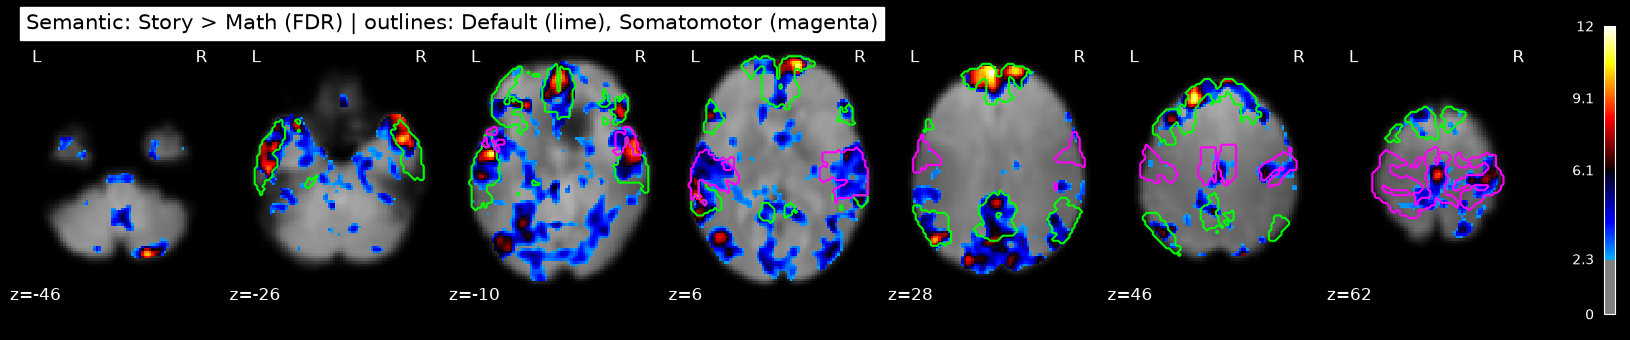

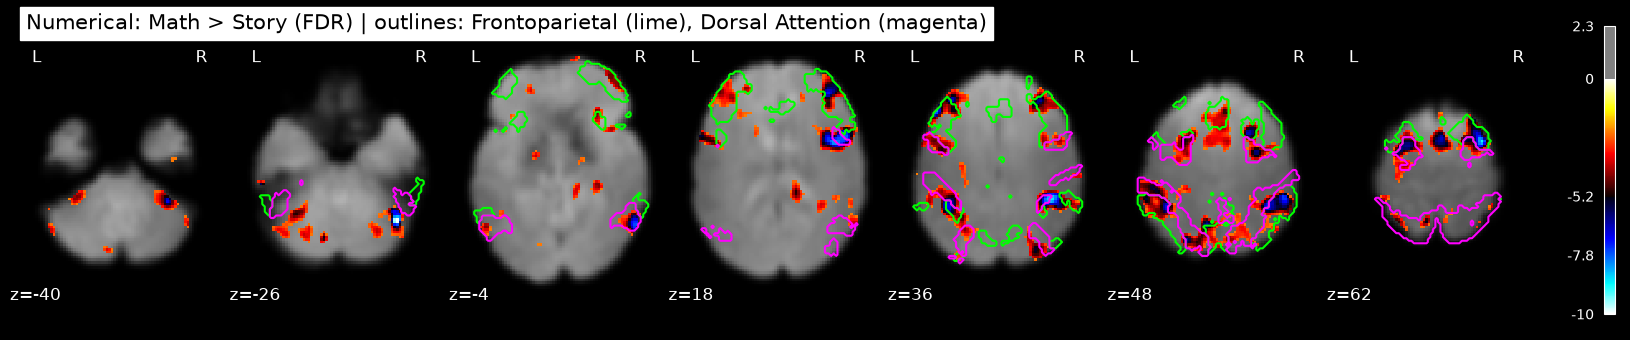

In [ ]:
# Since there are four most engaged networks: story > math (red) falls mostly in Default and Somatomotor, 
# while math > story (blue) mostly in Frontoparietal and Dorsal Attention, it is possible to plot these
# three networks and overlay them witht he clean z-map to see where they are on the brain. 

# Semantic processing: story > math voxels only (positive z), with the Default and Somatomotor outlines
story_map = nib.Nifti1Image(np.where(clean > 0, clean, 0), clean_map.affine)
fig_story = plot_stat_map(story_map, bg_img=mean_fmri, threshold=threshold, display_mode='z', cut_coords=7, black_bg=True,
                          title='Semantic: Story > Math (FDR) | outlines: Default (lime), Somatomotor (magenta)')
for k, color in [(7, 'lime'), (2, 'magenta')]:
    fig_story.add_contours(nib.Nifti1Image((yeo_data == k).astype(np.uint8), clean_map.affine),
                           levels=[0.5], colors=color, linewidths=1.5)
plt.show()

# Numerical processing: math > story voxels only (negative z), with the Frontoparietal and Dorsal Attention outlines
math_map = nib.Nifti1Image(np.where(clean < 0, clean, 0), clean_map.affine)
fig_math = plot_stat_map(math_map, bg_img=mean_fmri, threshold=threshold, display_mode='z', cut_coords=7, black_bg=True,
                         title='Numerical: Math > Story (FDR) | outlines: Frontoparietal (lime), Dorsal Attention (magenta)')
for k, color in [(6, 'lime'), (3, 'magenta')]:
    fig_math.add_contours(nib.Nifti1Image((yeo_data == k).astype(np.uint8), clean_map.affine),
                          levels=[0.5], colors=color, linewidths=1.5)
plt.show()

# Same images in FSLeyes
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(std_dir, 'MNI152_T1_2mm'))
fsleyesDisplay.load(yeo_path)
fsleyesDisplay.setOverlayCmap(1, 'Render3')
fsleyesDisplay.load(op.join(func_dir, 'story_minus_math_fdr.nii.gz'))

In [ ]:
# The same concept applies to the Harvard-Oxford atlas, to see in which anatomical regions the 
# significant voxels are located. It is also possible to see what is the functional network with 
# more voxels in that region, to have an idea of what should be the predominant functional
# network in that anatomical region. 

# In order to do so, it's necessary to distinguish when the voxel is in the right or left hemisphere. 
# This can be done defining what is our "x = 0 mm" in the template, then  x < 0 is the left hemisphere
x_mm = clean_map.affine[0, 0] * np.arange(clean.shape[0]) + clean_map.affine[0, 3]
left = (x_mm < 0)[:, None, None]

rows = []
for value, name in ho_labels.items(): # for every region (number in the Harvard-Oxford atlas and name)
    for hemi, side in [('L', left), ('R', ~left)]: # for left and right hemisphere separately
        roi = (ho_data == value) & side # mask of the region in the hemisphere

        # Count how many voxels have each each network label (0-7), dropping label 0 because it is outside of the cortex,
        # and keep the network with the most voxels (only for the networks that have at least one cortical voxel)
        region_labels = yeo_data[roi].astype(int)
        label_counts = np.bincount(region_labels, minlength=8) # how many voxels have label 0, 1, ..., 7
        network_counts = label_counts[1:]
        if network_counts.sum() > 0:
            network = yeo_names[network_counts.argmax()]
        else:
            network = '-' # no cortical voxels: no network

        rows.append([hemi + ' ' + name, network,
                     (roi & story_gt_math).sum(), 100 * (roi & story_gt_math).sum() / roi.sum(),   # story > math: # of voxels, % of region
                     (roi & math_gt_story).sum(), 100 * (roi & math_gt_story).sum() / roi.sum()])  # math > story: # of voxels, % of region

regions = pd.DataFrame(rows, columns=['Region', 'Predominant functional network', '# voxels where story > math', '% of region where story > math',
                                      '# voxels where math > story', '% of region where math > story']).set_index('Region')

# The 10 regions most engaged in each direction, ranked by % of region (so large regions do not win just by size)
print('Top 10 regions, story > math (semantic)')
display(regions.sort_values('% of region where story > math', ascending=False).head(10)[['Predominant functional network', '# voxels where story > math', '% of region where story > math']].round(1))
print('Top 10 regions, math > story (numerical)')
display(regions.sort_values('% of region where math > story', ascending=False).head(10)[['Predominant functional network', '# voxels where math > story', '% of region where math > story']].round(1))

Top 10 regions, story > math (semantic)


,Predominant functional network,# voxels where story > math,% of region where story > math
Region,,,
"L Superior Temporal Gyrus, anterior division",Default,253,100.0
L Cuneal Cortex,Visual,496,98.8
"R Superior Temporal Gyrus, anterior division",Default,262,97.8
R Cuneal Cortex,Visual,694,95.7
"L Middle Temporal Gyrus, anterior division",Default,423,94.8
L Planum Temporale,Somatomotor,488,91.6
"R Superior Temporal Gyrus, posterior division",Somatomotor,872,91.5
L Occipital Fusiform Gyrus,Visual,809,87.4
L Heschl's Gyrus (includes H1 and H2),Somatomotor,272,85.0


Top 10 regions, math > story (numerical)


,Predominant functional network,# voxels where math > story,% of region where math > story
Region,,,
"R Supramarginal Gyrus, posterior division",Frontoparietal,580,48.1
"R Inferior Frontal Gyrus, pars opercularis",Frontoparietal,287,43.8
"L Supramarginal Gyrus, anterior division",Ventral Attention,373,39.4
R Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex),Somatomotor,332,39.2
L Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex),Somatomotor,227,35.6
R Angular Gyrus,Default,496,33.9
R Middle Frontal Gyrus,Frontoparietal,862,33.7
L Middle Frontal Gyrus,Frontoparietal,847,30.7
"L Supramarginal Gyrus, posterior division",Frontoparietal,277,26.3


## 3f. Semantic regions

,% story>math (FDR),mean z,peak z,% in GLM mask,EPI intensity / brain median
Region,,,,,
L Temporal Pole,70.60,4.09,9.17,84.64,0.82
R Temporal Pole,67.22,4.43,10.22,88.18,0.89
"L Superior Temporal Gyrus, anterior division",100.00,6.64,11.21,100.00,1.04
"R Superior Temporal Gyrus, anterior division",97.76,6.55,10.81,100.00,1.09
"L Middle Temporal Gyrus, anterior division",94.84,5.85,10.42,99.10,0.90
"R Middle Temporal Gyrus, anterior division",76.87,4.78,10.51,97.76,0.96
"L Middle Temporal Gyrus, posterior division",49.21,2.70,9.94,93.39,0.81
"R Middle Temporal Gyrus, posterior division",31.95,2.23,8.73,80.96,0.72
"L Inferior Temporal Gyrus, anterior division",34.24,1.81,6.28,96.67,0.85


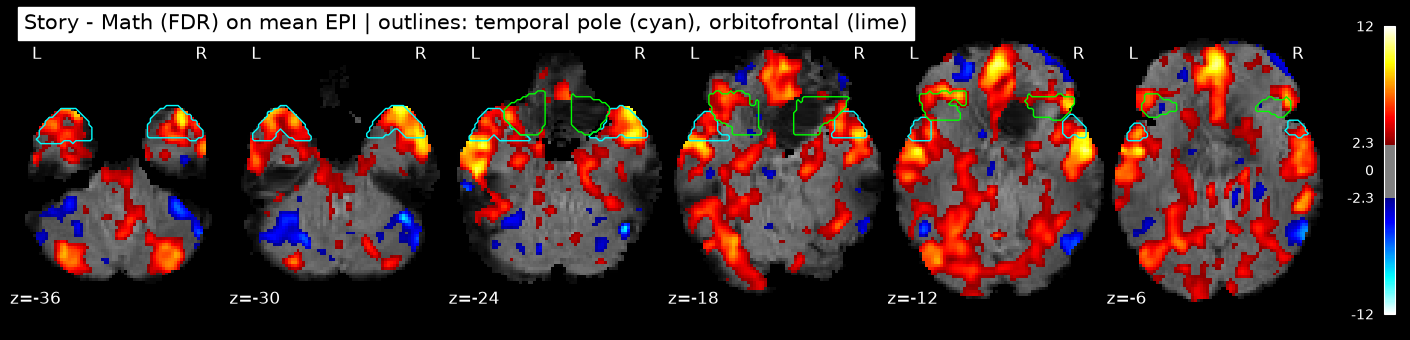

In [ ]:
# Semantic regions from the literature (Binder 2009; Binder 2011 for the ATL), as Harvard-Oxford labels
semantic_rois = ['Temporal Pole', 
                 'Superior Temporal Gyrus, anterior division', 
                 'Middle Temporal Gyrus, anterior division',
                 'Middle Temporal Gyrus, posterior division', 
                 'Inferior Temporal Gyrus, anterior division',
                 'Temporal Fusiform Cortex, anterior division', 
                 'Parahippocampal Gyrus, anterior division', 
                 'Angular Gyrus',
                 'Inferior Frontal Gyrus, pars triangularis', 
                 'Frontal Orbital Cortex', 
                 'Frontal Medial Cortex',
                 'Superior Frontal Gyrus', 
                 'Cingulate Gyrus, posterior division', 
                 'Precuneous Cortex']
ho_values = {name: value for value, name in ho_labels.items()}

z_all = z_map.get_fdata()                                  # unthresholded story - math z-map of 3d
glm_mask = fit_glm_sm.masker_.mask_img_.get_fdata() > 0    # voxels the GLM actually analysed
mean_epi_img = mean_img(moco + '.nii.gz')                  # mean EPI before smoothing: shows signal dropout
mean_epi = mean_epi_img.get_fdata()
brain_median = np.median(mean_epi[glm_mask])

rows = []
for name in semantic_rois:
    for hemi, side in [('L', left), ('R', ~left)]:
        roi = (ho_data == ho_values[name]) & side
        rows.append({'Region': '{} {}'.format(hemi, name),
                     '% story>math (FDR)': 100 * (roi & story_gt_math).sum() / roi.sum(),
                     'mean z': z_all[roi & glm_mask].mean(),
                     'peak z': z_all[roi & glm_mask].max(initial=-np.inf),
                     '% in GLM mask': 100 * (roi & glm_mask).sum() / roi.sum(),
                     'EPI intensity / brain median': mean_epi[roi].mean() / brain_median})
semantic = pd.DataFrame(rows).set_index('Region')
display(semantic.round(2))

# Report figure: ventral slices through the ATL and orbitofrontal cortex, on the mean EPI so dropout is visible
fig_f = plot_stat_map(clean_map, bg_img=mean_epi_img, threshold=threshold, display_mode='z',
                      cut_coords=[-36, -30, -24, -18, -12, -6], black_bg=True,
                      title='Story - Math (FDR) on mean EPI | outlines: temporal pole (cyan), orbitofrontal (lime)')
for name, color in [('Temporal Pole', 'cyan'), ('Frontal Orbital Cortex', 'lime')]:
    fig_f.add_contours(nib.Nifti1Image((ho_data == ho_values[name]).astype(np.uint8), clean_map.affine),
                       levels=[0.5], colors=color, linewidths=1)
plt.show()

## Towards PCA

In [ ]:
# cell needed for GLM <-> PCA alignment

import json
from pathlib import Path

shared_dir = Path.home() / "NSSP_outputs" / "shared_glm_pca"
shared_dir.mkdir(parents=True, exist_ok=True)


preprocessed_path = Path(smoothed)
if not str(preprocessed_path).endswith((".nii", ".nii.gz")):
    preprocessed_path = Path(str(preprocessed_path) + ".nii.gz")

preprocessed_path = preprocessed_path.resolve(strict=True)
export_img = nib.load(preprocessed_path)

assert len(design_mat) == export_img.shape[-1]
assert np.allclose(
    design_mat.index.to_numpy(dtype=float),
    np.arange(len(design_mat)) * tr,
    rtol=0,
    atol=1e-5,
)

design_mat.to_csv(
    shared_dir / "design_matrix.csv",
    index_label="frame_time_s",
)

metadata = {
    "fmri_path": str(preprocessed_path),
    "tr_s": float(tr),
    "start_vol": int(start_vol),
    "n_scans": int(export_img.shape[-1]),
    "columns": list(design_mat.columns),
    "task_regressors": sorted(events["trial_type"].unique().tolist()),
}

(shared_dir / "metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("File condivisi salvati in:", shared_dir)

# PCA

Now you proceed to do a different analysis by employing multivariate pattern  analysis methods (MVPA). The goal is to find spatial maps in a data-driven manner (no GLM) and to investigate which maps would include the regions found in the GLM analysis.   

Variant 1   
1. Apply PCA on the subject fMRI runs, considering one timepoint as one sample.   
2. Select a number of components of your choice to keep while providing a  justification for your choice. Show each of the selected PCA loadings  separately, in axial view only.    
3. Compute the correlation between the (temporal) scores associated to the first 10 components and the regressors of the GLM you performed in Part 1 (including all regressors that you deem appropriate). Report the correlation matrix and comment on the results, relating them to the spatial maps obtained at point 2.   

In [ ]:
## imports
import os
import os.path as op
from tqdm.notebook import trange, tqdm
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn.image import iter_img, resample_to_img
from nilearn.plotting import plot_stat_map, show
from sklearn.decomposition import FastICA, PCA

from nilearn import datasets
from nilearn.input_data import NiftiMasker
from scipy.stats import zscore
from scipy.io import loadmat
from IPython.display import Image

save_results = 'results/'
if not os.path.exists(save_results):
    os.makedirs(save_results)
    
%matplotlib inline

The steps involed in PCA are:  
1. centering the data by subtracting the sample mean from every observation  
2. computin ghte sample covariance matrix
3. eigendecomposition
Finally, we obrain the principal direction, and the varianca of the data across that principal direction.  

## Step 1

In [ ]:
## Load the data
# we need to load the fMRI runs
img = nib.load("/data/tsclient/NSSP/progetto/fMRI-20261015T140819Z-1-001/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz")
affine = img.affine
data = np.asanyarray(img.dataobj)
data.shape

(91, 109, 91, 316)

In [ ]:
vol_shape = data.shape[:3] # shape of the volumes
n_vols = data.shape[-1] # number of volumes

When applying PCa, a question that we need to ask is, what are the features and what are the samples?  
Here we take the timeponts as being the "samples" and the voxels to be the features".

First we reove the background because these voxels are useless.  
Then we will flatten the volume into a vector.

To verify the density distribution of the first volume in order to find the threshold to identidy the background we do the following:

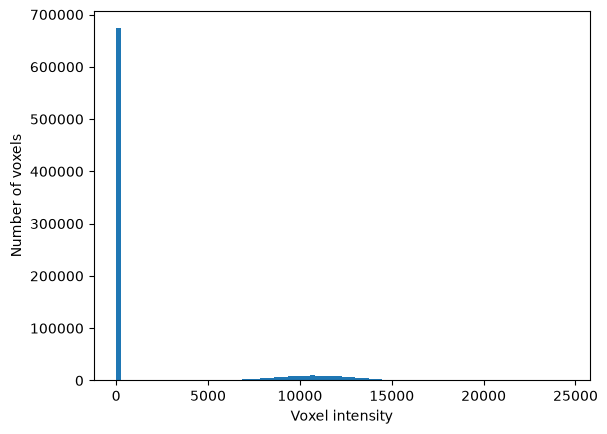

In [ ]:
plt.hist(data[:,:,:,0].ravel(), bins=100)
plt.xlabel("Voxel intensity")
plt.ylabel("Number of voxels")
plt.show()

From the figure above we see two main peaks: the first one is concentrated around zero and it represents the background's voxels (and they have a very low intensity), while the second one probably represents the signal coming from the brain tissues.  
We could take 500 as threshold, and to see if it enough to exclude the background we will compare the original fMRI with the brain mask obtained with the threshold at 500. 

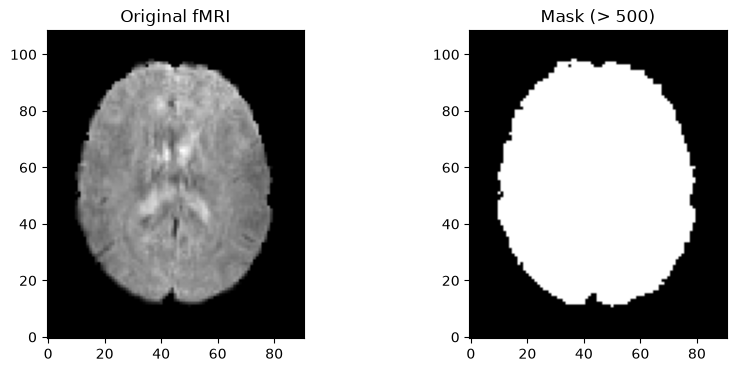

In [ ]:
# create mask
slice_non_background = data[:,:,:,0] > 500
# we take the middle slice
z = data.shape[2]//2
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(data[:,:,z,0].T, cmap="gray", origin = "lower")
plt.title("Original fMRI")
plt.subplot(1,2,2)
plt.imshow(slice_non_background[:,:,z].T, cmap="gray", origin="lower")
plt.title("Mask (> 500)")
plt.show()

From the image above we see that the background that is outside of the brain has been excluded. So we take 500 as threshold. 

In [ ]:
slice_non_background = data[:,:,:,0] > 500 
samples = np.array([data[:,:,:,i][slice_non_background] for i in range(n_vols)])

Next we will remove the spatial mean across timepoints from each timepoint.  
Calculate the mean spatial pattern and perform substraction operation. 

In [ ]:
spatial_means = samples.mean(axis=1)
row_means = spatial_means[:, np.newaxis]
X = samples - row_means
print(X.mean(axis=1)) 

[ 2.4429400e-04  7.4160675e-04 -3.2281707e-04  4.3623926e-04
 -1.0469742e-04 -2.7046836e-04 -2.1811963e-04  1.0382495e-03
  2.4429400e-04 -1.7449571e-04  1.3959657e-04  1.0469742e-03
 -3.5771620e-04 -6.8925804e-04  6.9798283e-05  7.6778111e-04
 -3.2281707e-04  1.0993229e-03  6.1073501e-05 -1.2040203e-03
 -1.9194528e-04 -4.8858800e-04 -9.1610244e-04 -2.8791791e-04
  1.8322049e-04 -1.1691212e-03 -5.9328543e-04 -6.1073501e-05
 -3.9261533e-04 -5.3221191e-04 -7.8523066e-05  1.1167725e-03
 -4.0134013e-04 -1.8322049e-04  5.2348711e-05 -4.1006491e-04
 -6.8925804e-04 -9.0737769e-04 -1.0120751e-03  5.9328543e-04
  8.5502898e-04  1.4832136e-04  1.0469742e-04 -1.1342221e-04
 -9.5972639e-05  8.0268027e-04 -2.0067007e-04  1.3959657e-04
 -1.1865709e-03 -6.7180849e-04 -5.9328543e-04  1.0469742e-03
  7.1543240e-04 -1.3872408e-03 -6.1073501e-05 -2.4429400e-04
 -1.6577092e-04  1.2650939e-03  5.2348711e-05  2.7046836e-04
 -1.6577092e-03 -3.5771620e-04  3.4899142e-05  2.7919313e-04
 -1.9194528e-04  4.36239

In [ ]:
X.shape

(316, 229232)

X represents the fMRI data matrix after the mean subtraction for each volume.  
Each value of x represents how much the voxel intensity differs from the spatial mean of its volume.  
X is a martrix (n volumes x n voxels)  
Its rows are the samples (timepoints).  
Its columns are the features (voxels).  

## Part 2

Now we perform component extraction.  
By applying PCA on the temporal axis, we are finding reresentatives of spatial clusters. In our case, the components that we find best represent the full run.  
To chose the number of componts to use we will use the elbow Criterion, which enables us to see from what component on we don't gain much more information if we would take into account one more.  

In [ ]:
from sklearn.decomposition import PCA
nb_components = 30 # we first start with an arbitrary number 
pca = PCA(nb_components)
pca.fit(X)

print(pca.explained_variance_ratio_)

[0.07083717 0.02705508 0.02607731 0.025969   0.01562419 0.014182
 0.01325985 0.01189232 0.01077476 0.00949956 0.00874828 0.00864553
 0.00808182 0.00635961 0.00553465 0.00519861 0.00497562 0.00481029
 0.00471724 0.00457199 0.00447617 0.00443281 0.00420054 0.00406766
 0.00399058 0.00394929 0.00384403 0.00371539 0.0036998  0.00351175]


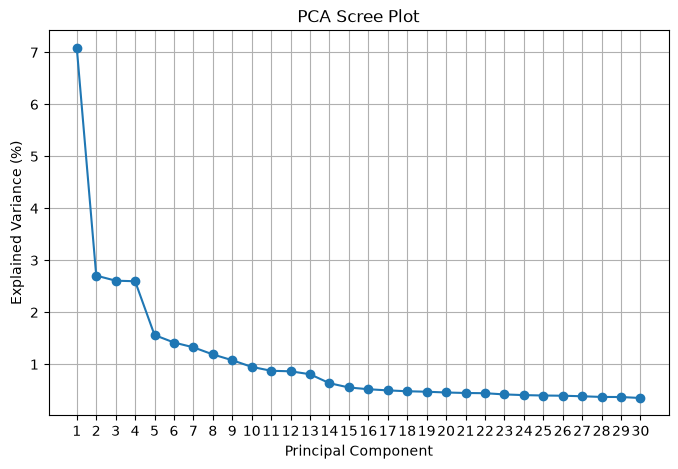

In [ ]:
# to chose the number of components we use the Scree Plot
explained_variance = pca.explained_variance_ratio_
plt.figure(figsize=(8,5))
plt.plot(range(1, len(explained_variance) +1), explained_variance * 100, marker = 'o')
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)
plt.show()

From the plot above we see that the first four PC are the ones that explain the variance the most so we keep just them four.   


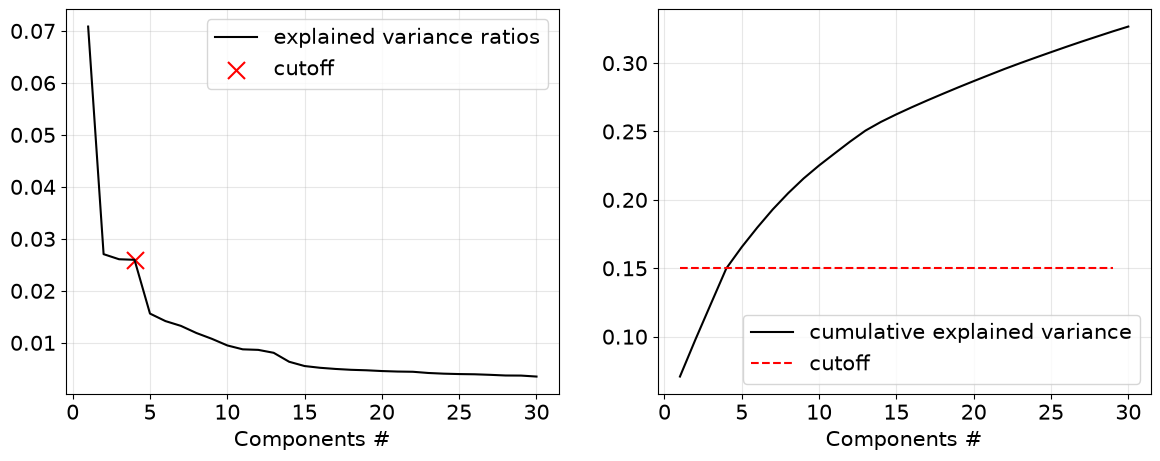

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))

ratios = pca.explained_variance_ratio_
cumulative_ratios = np.cumsum(pca.explained_variance_ratio_)

nb_clusters = 4 # this is the number of components that we chose to keep 
ax[0].plot(np.arange(1, len(ratios)+1), ratios, label='explained variance ratios', c='k')
ax[0].scatter([nb_clusters], [ratios[nb_clusters-1]], [150], marker='x', color='r', label='cutoff')
ax[1].plot(np.arange(1, len(cumulative_ratios)+1), cumulative_ratios, label='cumulative explained variance', c='k')
ax[1].hlines(y=cumulative_ratios[nb_clusters-1], xmin=1, xmax=len(ratios)-1, linestyle='--', color='r', label='cutoff')

for k in range(2):
    ax[k].set_xlabel('Components #', size=15)
    ax[k].legend(prop={'size':15})
    ax[k].tick_params(axis='both', which='major', labelsize=15)

    ax[k].grid(True, alpha=0.3)

Now that we selected components of interest let's bring the vectors back to the original spatial domain. 
In order to do this, wereshape the components back to the original volume shape, while remembering that we removed the background voxels.

In [ ]:
# final PCA with 4 selected components
nb_components = 4
pca = PCA(nb_components)
pca.fit(X)


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",4
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [ ]:
pca_clusters = [] # List of spatial components 
for component in pca.components_: # we take one PCA component at a time
    volume = np.zeros(vol_shape) # create a 3D volume with the same shape as the original image
    volume[slice_non_background]=component # insert the weights of the component in the voxel's positions that we saved, and we keep the backgroud to zero
    pca_clusters.append(volume) 

print(len(pca_clusters))
print(pca_clusters[0].shape)

4
(91, 109, 91)


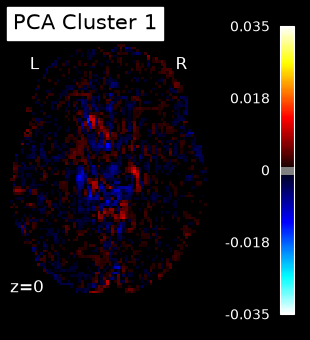

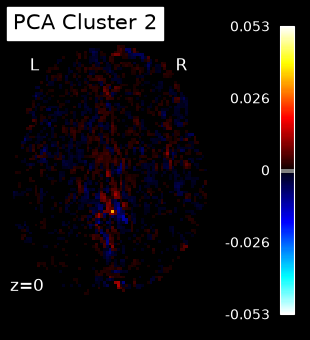

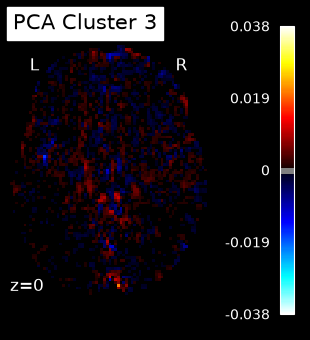

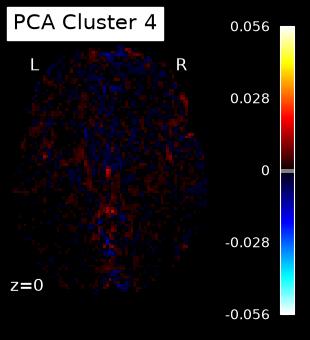

In [ ]:
# show each of the selected PCA loadings separately, in axial view only
from nilearn.plotting import plot_stat_map

for visual_idx in range(4):
    plot_stat_map(nib.Nifti1Image(pca_clusters[visual_idx], affine), bg_img=None, threshold=1e-3, display_mode = "z", # visualize axis plane
                   cut_coords=[0], # visualize the axial session at coordinate z = 0
                  black_bg=True, 
                  title=f'PCA Cluster {visual_idx+1}')

plt.show()

# Final PCA analysis on the GLM input

Start with a clean kernel and run this section from its import cell to the end. It is self-contained and uses the same preprocessed fMRI run and numerical design matrix as the GLM. It follows the Lab 7 sequence: inspect the data and mask, form timepoint-by-voxel samples, subtract each volume's spatial mean, fit PCA, inspect explained variance and reconstruct spatial loadings.

The preceding exploratory analysis uses a different input and is not required to run this section. Its saved figures must not be combined with these final results. A full Run All still depends on the earlier cells' own paths and imports; running directly from this heading avoids those unrelated prerequisites.

The task-specific additions are axial-only spatial maps, temporal scores for the first ten components, correlations with the exported GLM regressors and interpretation. Files are read from and saved to the shared tsclient drive using the Part 1 directory convention. No subject results are assumed before execution.


In [ ]:
# Import the libraries used for PCA and the GLM comparison
import os
import os.path as op
import json
import pandas as pd
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn.plotting import plot_stat_map
from sklearn.decomposition import PCA

# Project directories
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(op.join(notebook_dir, '..'))
data_dir = '/home/jovyan/data/tsclient/NSSP/progetto'
output_dir = op.join(data_dir, 'outputs')

# Paths for Luca
#data_dir = '/home/jovyan/data/tsclient/Projects/Project_1/miniproject_2026_final'
#output_dir = '/home/jovyan/data/tsclient/Projects/Project_1/Outputs'

# Store derivatives on the shared drive for persistence
shared_dir = op.join(output_dir, 'shared_glm_pca')
save_results = op.join(output_dir, 'pca')
if not op.isdir(data_dir):
    raise FileNotFoundError('Dataset directory not accessible: ' + data_dir)
os.makedirs(save_results, exist_ok=True)

print('Notebook directory:', notebook_dir)
print('Project directory:', parent_dir)
print('Data directory:', data_dir)
print('Output directory:', output_dir)
print('Shared GLM files:', shared_dir)
print('PCA results:', save_results)

%matplotlib inline

PCA finds orthogonal spatial directions ordered by explained variance. Following the Lab 7 sequence, we load the fMRI run, inspect a foreground mask, form a timepoint-by-voxel matrix, subtract the spatial mean of each volume, fit PCA, inspect explained variance and reconstruct the selected spatial maps.

Spatial-mean subtraction acts across masked voxels within each volume. Scikit-learn subsequently centers each voxel across time during fitting. These are distinct operations; no voxel-wise variance standardization is applied.

Spatial loadings are stored in `pca.components_`. Projecting the data with `pca.transform(X)` gives the corresponding temporal scores. GLM regressors are used only to interpret these scores after fitting PCA.

## Step 1: Load the shared fMRI run

Run this notebook from the repository's `notebooks` directory in the VM. Inputs and persistent derivatives follow the Part 1 shared-drive convention: `data_dir` points to `/home/jovyan/data/tsclient/NSSP/progetto`, `output_dir` is `data_dir/outputs`, and PCA results are saved in `output_dir/pca`. The commented paths in the setup cell describe Luca's directory layout.

Use the same already-trimmed, motion-corrected and 6 mm-smoothed series used by the GLM. The GLM must export `design_matrix.csv`, indexed by `frame_time_s`, and `metadata.json` into `output_dir/shared_glm_pca`. The earlier `design_matrix_metadata.json` export is also accepted. The GLM export instructions below use the same shared-drive directory.

The metadata identify the input image, TR, removed initial volumes, retained volume count, task regressors and design columns. The image path must identify the actual preprocessed file used by the GLM and be readable inside the VM. Keep that input among the persistent Part 1 derivatives; regenerate the export if the file is moved. Do not remove the initial volume again or shift the events a second time. Spike regressors model outlier volumes without removing them from this series.

We reuse all nonconstant regressors actually exported by the GLM, including task sub-events if present, motion, polynomial drift and outlier spikes. Overlapping task regressors can have similar temporal associations; marginal correlations do not separate their unique effects. The 6 mm smoothing is retained for consistency with the GLM, although it reduces spatial detail. These files are sufficient for temporal correlations; a fitted GLM is needed only for the later comparison of spatial maps.

In [ ]:
# Read the numerical design and the metadata for the same fMRI run
design_path = op.join(shared_dir, 'design_matrix.csv')
metadata_path = op.join(shared_dir, 'metadata.json')
if not op.isfile(metadata_path):
    metadata_path = op.join(shared_dir, 'design_matrix_metadata.json')
if not (op.isfile(design_path) and op.isfile(metadata_path)):
    raise FileNotFoundError(
        'Export design_matrix.csv and metadata.json from the GLM to '
        + shared_dir + ', or set shared_dir to the export folder.'
    )

with open(metadata_path, 'r', encoding='utf-8') as f:
    metadata = json.load(f)
design_mat = pd.read_csv(design_path, index_col='frame_time_s')

img = nib.load(metadata['fmri_path'])
assert len(img.shape) == 4, 'PCA requires a 4D fMRI time series.'
affine = img.affine

# Both export formats describe the same image and design conventions
tr = float(metadata['tr_s'] if 'tr_s' in metadata else metadata['tr_seconds'])
design_columns = metadata['columns'] if 'columns' in metadata else metadata['design_columns']
task_regressors = metadata['task_regressors'] if 'task_regressors' in metadata else metadata['task_types']
start_vol = metadata['start_vol']
frame_times = np.arange(img.shape[-1]) * tr

# Check timepoint identity before loading the full image
assert np.isfinite(tr) and tr > 0, 'Invalid TR.'
assert isinstance(start_vol, int) and start_vol >= 0
assert img.shape[-1] == metadata['n_scans'] == len(design_mat), 'Image/design length mismatch.'
assert np.isclose(img.header.get_zooms()[3], tr, rtol=0, atol=1e-5), 'Image/design TR mismatch.'
assert design_mat.index.is_unique, 'Repeated frame times.'
assert np.allclose(design_mat.index.to_numpy(dtype=float), frame_times, rtol=0, atol=1e-5), 'Frame times must start at the first retained volume.'
assert list(design_mat.columns) == design_columns, 'Design columns differ from the metadata.'
assert design_mat.columns.is_unique, 'Repeated regressor names.'
assert np.isfinite(design_mat.to_numpy(dtype=float)).all(), 'Non-finite design values.'
assert task_regressors and set(task_regressors).issubset(design_mat.columns), 'Missing task regressors.'

if 'total_volumes' in metadata:
    assert img.shape[-1] == metadata['total_volumes'] - start_vol, 'Unexpected retained volume count.'
if 'frame_time_origin' in metadata:
    assert metadata['frame_time_origin'] == 'first_retained_volume'
if 'onset_shift_seconds' in metadata:
    assert np.isclose(metadata['onset_shift_seconds'], start_vol * tr)

# Outlier indices refer to the retained series
if 'outlier_volumes_trimmed' in metadata:
    outlier_volumes = np.asarray(metadata['outlier_volumes_trimmed'], dtype=int)
    assert np.all((outlier_volumes >= 0) & (outlier_volumes < len(design_mat)))
    assert len(np.unique(outlier_volumes)) == len(outlier_volumes)
    for i, volume_idx in enumerate(outlier_volumes):
        expected_spike = np.zeros(len(design_mat))
        expected_spike[volume_idx] = 1
        assert np.array_equal(design_mat[f'motion outlier#{i+1}'].to_numpy(), expected_spike), 'Spike indices differ from the metadata.'

data = img.get_fdata(dtype=np.float32)
print('Shared input:', metadata['fmri_path'])
print('Shape:', data.shape, '| TR:', tr, 's')
print('Initial volumes already removed:', start_vol)
print('Task regressors:', task_regressors)

In [ ]:
vol_shape = data.shape[:3]  # Shape of each volume
n_vols = data.shape[-1]  # Number of retained timepoints

### Preprocessing

Each timepoint is one sample and each masked voxel is one feature. Background voxels are excluded before flattening the spatial dimensions. The same mask and voxel order are used to reconstruct the spatial loading maps.

Inspect the intensity distribution of the first retained volume before choosing a background threshold.

In [ ]:
plt.hist(data[:,:,:,0].ravel(), bins=100)
plt.xlabel("Voxel intensity")
plt.ylabel("Number of voxels")
plt.show()

Inspect the histogram on the **current shared preprocessed input**. The original code used 500 to separate low-intensity background from tissue. Keep that lab-style threshold provisionally, but verify it again after preprocessing: intensity scales vary and this is not an anatomical brain extraction.

In [ ]:
# Select foreground voxels from the first retained volume
slice_non_background = data[:, :, :, 0] > 500
z = data.shape[2] // 2

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(data[:, :, z, 0].T, cmap='gray', origin='lower')
plt.title('Preprocessed fMRI')
plt.subplot(1, 2, 2)
plt.imshow(slice_non_background[:, :, z].T, cmap='gray', origin='lower')
plt.title('Mask (> 500)')
plt.tight_layout()
plt.savefig(op.join(save_results, 'pca_mask_check.png'), dpi=200, bbox_inches='tight')
plt.show()

Inspect the image and mask before continuing. Check that relevant tissue is retained and the background is excluded on the current preprocessed input. The intensity threshold is an empirical choice, not an anatomical brain extraction, and need not match the GLM's automatically estimated mask.

In [ ]:
# Rows are timepoints; columns are masked voxels
assert slice_non_background.any(), 'Empty mask: inspect the intensity threshold.'
samples = np.array([data[:, :, :, i][slice_non_background] for i in range(n_vols)])
assert samples.shape == (n_vols, int(slice_non_background.sum()))
assert np.isfinite(samples).all(), 'Masked fMRI contains NaN/Inf.'
print('Timepoints x masked voxels:', samples.shape)

Subtract the spatial mean of each volume across its masked voxels, as in Lab 7. Compute the mean across columns (`axis=1`), give the row means a singleton feature dimension and subtract them from `samples`. Inspect the remaining row means before fitting. Scikit-learn then also centers each voxel across time internally. No voxel-wise variance standardization or GLM confound regression is applied here.

This step removes volume-wise global offsets, including any task-related variation expressed as a spatially uniform offset within the mask. The GLM and PCA retain the same observations and time reference, but their masks and signal transformations are not identical. Interpret their agreement and differences with this preprocessing distinction in mind.

In [ ]:
# Calculate the spatial mean across masked voxels for each timepoint
spatial_means = samples.mean(axis=1)
row_means = spatial_means[:, np.newaxis]
X = samples - row_means
assert np.isfinite(X).all()

# Inspect the spatial mean after subtraction
print(X.mean(axis=1))

In [ ]:
X.shape

`X` has shape `(n_vols, n_masked_voxels)`. Rows are timepoints and columns are masked voxels. Each value expresses a voxel's intensity relative to the spatial mean of its volume. The PCA estimator also subtracts voxel temporal means during fitting.

## Part 2: Components extraction

Fit PCA with timepoints as samples and voxels as features. The components are continuous spatial loading patterns, not clusters or GLM activation maps. Retain up to 30 components to inspect individual and cumulative explained variance. At least 10 components must remain available for the score-regressor correlations, even when fewer spatial maps are selected.

In [ ]:
# Retain enough components for the scree plot and temporal correlations
nb_components = min(30, X.shape[0] - 1, X.shape[1])
if nb_components < 10:
    raise ValueError('At least ten components are needed for this analysis.')

pca = PCA(nb_components, random_state=0)
pca.fit(X)
assert np.isfinite(pca.explained_variance_ratio_).all(), 'Undefined explained variance.'
print(pca.explained_variance_ratio_)

In [ ]:
# Inspect the explained variance of successive components
explained_variance = pca.explained_variance_ratio_
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance) + 1), 100 * explained_variance, marker='o')
plt.xlabel('Principal component')
plt.ylabel('Explained variance (%)')
plt.title('PCA scree plot')
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)
plt.tight_layout()
plt.savefig(op.join(save_results, 'pca_scree.png'), dpi=200, bbox_inches='tight')
plt.show()

Four components are an initial display choice. Confirm or revise this number using the current scree plot, cumulative explained variance and spatial interpretability. Explain any change in slope and quote the actual retained percentage; the fact that earlier components explain more variance is not sufficient justification. The assignment does not impose a 95% variance target. Temporal correlations still use the first ten components.

In [ ]:
# Select the number of spatial maps to display
nb_clusters = 4
assert 1 <= nb_clusters <= pca.n_components_

ratios = pca.explained_variance_ratio_
cumulative_ratios = np.cumsum(ratios)
component_numbers = np.arange(1, len(ratios) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(component_numbers, 100 * ratios, 'o-')
ax[0].axvline(nb_clusters, color='red', linestyle='--', label='Selected maps')
ax[0].set_ylabel('Explained variance (%)')
ax[0].set_title('Scree plot')

ax[1].plot(component_numbers, 100 * cumulative_ratios, 'o-')
ax[1].axvline(nb_clusters, color='red', linestyle='--', label='Selected maps')
ax[1].set_ylabel('Cumulative explained variance (%)')
ax[1].set_title('Cumulative variance')

for k in range(2):
    ax[k].set_xlabel('Number of components')
    ax[k].legend()
    ax[k].grid(True, alpha=0.3)

print(f'First {nb_clusters} PCs: {100 * cumulative_ratios[nb_clusters - 1]:.2f}% of total variance')
fig.tight_layout()
fig.savefig(op.join(save_results, 'pca_variance_selection.png'), dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame({
    'component': component_numbers,
    'explained_variance_ratio': ratios,
    'cumulative_explained_variance_ratio': cumulative_ratios,
}).to_csv(op.join(save_results, 'pca_explained_variance.csv'), index=False)

Reconstruct each selected loading vector on the original image grid, using the same mask and voxel order. The fitted PCA is kept intact so that maps and temporal scores refer to the same directions. Signed loadings represent a component's spatial pattern, not statistical significance or hard cluster assignments.

In [ ]:
# Project the timepoints onto the first ten fitted spatial directions
nb_components = nb_clusters
scores = pca.transform(X)[:, :10]
assert scores.shape == (n_vols, 10)
assert np.isfinite(scores).all()

In [ ]:
# Put the selected loading vectors back into the image grid
pca_clusters = []
for component in pca.components_[:nb_components]:
    volume = np.zeros(vol_shape, dtype=np.float32)
    volume[slice_non_background] = component
    pca_clusters.append(volume)

print('Selected spatial maps:', len(pca_clusters))
print('Spatial shape:', pca_clusters[0].shape)

In [ ]:
# Show each spatial loading map separately in axial view
mean_fmri = nib.Nifti1Image(data.mean(axis=-1), affine, img.header.copy())
common_vmax = float(np.max(np.abs(pca.components_[:nb_components])))

for visual_idx in range(nb_components):
    component_img = nib.Nifti1Image(pca_clusters[visual_idx], affine, img.header.copy())
    component_img.set_data_dtype(np.float32)
    component_img.to_filename(op.join(save_results, f'PC{visual_idx + 1:02d}_loadings.nii.gz'))

    # Display the largest absolute weights; this is not a significance threshold
    visual_threshold = float(np.percentile(np.abs(pca.components_[visual_idx]), 95))
    component_display = plot_stat_map(
        component_img, bg_img=mean_fmri, display_mode='z', cut_coords=5,
        threshold=visual_threshold, cmap='RdBu_r', symmetric_cbar=True,
        vmax=common_vmax,
        title=f'PC{visual_idx + 1} | variance {100 * ratios[visual_idx]:.2f}%',
    )
    component_display.savefig(op.join(save_results, f'PC{visual_idx + 1:02d}_axial.png'), dpi=200)
    plt.show()
    component_display.close()

## Part 3: Correlation with the GLM regressors

This extends the Lab 7 PCA workflow to the miniproject requirement: selected spatial maps and the first ten score timecourses are taken from the same fitted model, without a second fit. Each selected loading map is displayed separately in axial view.

Compare the first ten temporal scores with the exact exported design, including HRF-convolved task regressors and nuisance columns. Constant columns are excluded because Pearson correlation is undefined for them. Do not convolve the BOLD-derived scores with another HRF. Regressors enter only this interpretation step, not the PCA fit.

Correlations are descriptive marginal associations, not partial GLM effects or corrected activation tests. Correlated task regressors may share the same association. Motion, drift and spike associations help identify nuisance-dominated components; these effects have not been regressed out of the PCA input. Temporal autocorrelation prevents treating all scans as independent observations for naive significance tests.

A spatial map and its score can both reverse sign without changing the reconstruction. Interpret the sign together with the map, rather than labelling a component as activation or deactivation from the score alone.

In [ ]:
# Keep score rows on the same frame-time index as the GLM design
assert scores.shape[0] == len(design_mat) == n_vols
score_columns = [f'PC{i+1}' for i in range(10)]
score_df = pd.DataFrame(scores, index=design_mat.index, columns=score_columns)
score_df.index.name = 'frame_time_s'

# Exclude constant columns only from the correlation calculation
regressor_columns = [c for c in design_mat.columns if design_mat[c].std(ddof=0) > 1e-12]
excluded_columns = [c for c in design_mat.columns if c not in regressor_columns]
print('Constant columns excluded from Pearson r:', excluded_columns)
assert regressor_columns, 'No variable GLM regressors.'
assert (score_df.std(ddof=0) > 1e-12).all(), 'A component score has zero variance.'

# Compare temporal scores with task, motion, drift and spike regressors
pca_regressor_corr = pd.DataFrame(index=score_columns, columns=regressor_columns, dtype=float)
for component in score_columns:
    for regressor in regressor_columns:
        pca_regressor_corr.loc[component, regressor] = score_df[component].corr(design_mat[regressor])

assert np.isfinite(pca_regressor_corr.to_numpy()).all(), 'Undefined correlation.'
assert (np.abs(pca_regressor_corr.to_numpy()) <= 1 + 1e-12).all()

plt.figure(figsize=(max(10, 0.55 * len(regressor_columns)), 6))
plt.imshow(pca_regressor_corr, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(label='Pearson r')
plt.xticks(range(len(regressor_columns)), regressor_columns, rotation=90, fontsize=8)
plt.yticks(range(10), score_columns)
plt.title('First 10 PCA temporal scores vs GLM regressors')
plt.tight_layout()
plt.savefig(op.join(save_results, 'pca_regressor_correlations.png'), dpi=200, bbox_inches='tight')
plt.show()

score_df.to_csv(op.join(save_results, 'pca_scores_first10.csv'))
pca_regressor_corr.to_csv(op.join(save_results, 'pca_regressor_correlations.csv'))
pca_regressor_corr

### Relate temporal associations to the spatial maps

For each selected component, report its explained variance, the strongest task associations and the main regions visible in its loading map. Check whether a stronger association with motion, drift or a spike suggests a nuisance contribution. Inspect the loading map of a component beyond the displayed set before making anatomical claims about it.

Complete the interpretation after running the subject data: **PC ... explains ...% of total variance and correlates with ... (r = ...). Its loading map shows prominent weights in ... . The association with ... limits/supports a task-related interpretation because ... .** The table below is a descriptive aid, not a significance test. Four displayed maps and the intensity threshold remain choices to justify from the current figures.

In [ ]:
# Summarize the strongest task and nuisance association for each score
task_columns = [c for c in task_regressors if c in regressor_columns]
nuisance_columns = [c for c in regressor_columns if c not in task_regressors]
assert task_columns, 'No variable task regressors are available.'

summary_rows = []
for component in score_columns:
    best_task = pca_regressor_corr.loc[component, task_columns].abs().idxmax()
    row = {
        'PC': component,
        'explained_variance_percent': 100 * pca.explained_variance_ratio_[score_columns.index(component)],
        'strongest_task': best_task,
        'task_r': pca_regressor_corr.loc[component, best_task],
    }
    if nuisance_columns:
        best_nuisance = pca_regressor_corr.loc[component, nuisance_columns].abs().idxmax()
        row['strongest_nuisance'] = best_nuisance
        row['nuisance_r'] = pca_regressor_corr.loc[component, best_nuisance]
    summary_rows.append(row)

pca_task_summary = pd.DataFrame(summary_rows)
pca_task_summary.to_csv(op.join(save_results, 'pca_task_summary.csv'), index=False)
pca_task_summary.round(3)

### Compare with the GLM spatial results

Temporal correlations require only the design matrix; anatomical comparison additionally requires the fitted GLM maps. Place `glm_story_z.nii.gz`, `glm_math_z.nii.gz` and `glm_story_minus_math_z.nii.gz` in `shared_dir` when they are available. The next cell displays those maps without a statistical threshold, for descriptive inspection. Use the inferential thresholds and correction chosen in Part 1 before calling a region significantly activated.

Compare labelled axial coordinates and visible anatomical landmarks with the PCA maps. A common array shape or a matching filename does not establish anatomical registration. For a figure showing direct correspondence, select the same axial world coordinates in both plots after verifying their common spatial reference. PCA loading magnitudes and GLM z scores have different units and must not share a numerical interpretation.

If the GLM includes both whole blocks and their nested sub-events, its story/math coefficients are conditional on the other regressors. They are not automatically the overall task effects of a block-only model. Similar temporal associations therefore need a cautious spatial interpretation.

In [ ]:
# Inspect available GLM maps without interrupting the temporal analysis
glm_map_names = ['story', 'math', 'story_minus_math']
for map_name in glm_map_names:
    glm_map_path = op.join(shared_dir, f'glm_{map_name}_z.nii.gz')
    if op.isfile(glm_map_path):
        glm_display = plot_stat_map(
            glm_map_path, bg_img=mean_fmri, display_mode='z', cut_coords=5,
            threshold=0, cmap='RdBu_r', symmetric_cbar=True,
            title=f'GLM {map_name}: unthresholded z scores',
        )
        glm_display.savefig(op.join(save_results, f'glm_{map_name}_axial.png'), dpi=200)
        plt.show()
        glm_display.close()
    else:
        print('GLM map not available:', glm_map_path)

## Theoretical questions

**1. What changes if one voxel is one sample?**

With timepoints as samples, the matrix is T x V: each spatial component has V weights and T temporal scores. With voxels as samples, it becomes V x T: each component has T weights describing a temporal pattern, and V scores describing its expression across voxels. The analysis would then summarize differences between voxel timecourses. Centering would also act along a different sample axis, so transposing the previous outputs alone would not reproduce the new analysis.

**2. Is comparison with the GLM conceptually appropriate?**

The methods provide complementary descriptions of the same observations when the retained timepoints and regressors are aligned. A GLM tests associations with a design specified in advance and supports task contrasts voxel by voxel. PCA finds orthogonal patterns that maximize explained variance without using the task labels. Correlating temporal scores with the design helps interpret these patterns; comparing loading maps with GLM maps addresses their spatial distribution. A correlation does not establish equivalence with a GLM effect because a component can mix task, motion and physiological variability. We would use GLM for predefined hypotheses and inferential contrasts, and PCA for exploration, dimensionality reduction and identifying dominant patterns or artefacts.

## Preparing the shared files in the GLM session

Run the following in the GLM notebook after building `design_mat`, with `fmri_img` loaded from the preprocessed series actually used by the model. Use the same `data_dir` selected in the PCA setup cell. The export is stored under `data_dir/outputs/shared_glm_pca` on the shared drive. It does not fit PCA or rebuild the GLM design. If `make_first_level_design_matrix` is missing from the GLM imports, import it from `nilearn.glm.first_level` before building the design.

```python
import json

shared_dir = op.join(data_dir, 'outputs', 'shared_glm_pca')
os.makedirs(shared_dir, exist_ok=True)
assert len(design_mat) == fmri_img.shape[-1]
assert np.allclose(design_mat.index.to_numpy(dtype=float),
                   np.arange(len(design_mat)) * tr, rtol=0, atol=1e-5)
design_mat.to_csv(op.join(shared_dir, 'design_matrix.csv'),
                  index_label='frame_time_s')
metadata = {
    'fmri_path': op.abspath(fmri_img.get_filename()),
    'tr_s': float(tr),
    'start_vol': int(start_vol),
    'n_scans': int(fmri_img.shape[-1]),
    'columns': list(design_mat.columns),
    'task_regressors': sorted(events['trial_type'].unique().tolist()),
}
with open(op.join(shared_dir, 'metadata.json'), 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)
```

After fitting the GLM successfully, the following optional export supplies the maps used in the spatial comparison. The contrast weights follow the actual fitted design column order. These exports are unthresholded z maps, not corrected activation results.

```python
fitted_design = fit_glm.design_matrices_[0]
columns = list(fitted_design.columns)
assert columns == list(design_mat.columns)
assert np.allclose(fitted_design.to_numpy(), design_mat.to_numpy())
story_contrast = np.zeros(len(columns))
math_contrast = np.zeros(len(columns))
story_contrast[columns.index('story')] = 1
math_contrast[columns.index('math')] = 1
contrasts = {
    'story': story_contrast,
    'math': math_contrast,
    'story_minus_math': story_contrast - math_contrast,
}
for name, contrast in contrasts.items():
    z_map = fit_glm.compute_contrast(contrast, output_type='z_score')
    z_map.to_filename(op.join(shared_dir, f'glm_{name}_z.nii.gz'))
```

Use the acquisition TR and the exported frame-time grid; do not copy a tutorial TR such as 7 s into this analysis. If paths or upstream GLM choices change, regenerate the shared exports in the VM. Subject variance values, mask quality and anatomical conclusions must come from the real execution, not earlier saved outputs or synthetic checks.